# Proyecto 2 - *Fine-tuning* de Transformers para tareas de NLP

**Universidad de Antioquia** · Fundamentos en Procesamiento de Lenguaje Natural

**Estudiante:** Felipe Uribe Holguin

En este notebook se ajustan (*fine-tuning*) modelos Transformer preentrenados para resolver tres tipos de problemas de NLP:

| # | Tipo de problema | Tarea concreta | Base de datos (Hugging Face) | Modelo base |
|---|---|---|---|---|
| A | Clasificación de secuencias | Análisis de sentimiento (negativo / neutral / positivo) de reseñas de productos en español | [`SetFit/amazon_reviews_multi_es`](https://huggingface.co/datasets/SetFit/amazon_reviews_multi_es) | BETO — [`dccuchile/bert-base-spanish-wwm-cased`](https://huggingface.co/dccuchile/bert-base-spanish-wwm-cased) (tipo **BERT**) |
| B | Etiquetado de secuencias | Reconocimiento de entidades nombradas (NER) en noticias en español | [`BramVanroy/conll2002`](https://huggingface.co/datasets/BramVanroy/conll2002) (config. `es`) | BETO (tipo **BERT**) |
| C | Secuencia a secuencia | Traducción automática inglés → español de textos literarios | [`Helsinki-NLP/opus_books`](https://huggingface.co/datasets/Helsinki-NLP/opus_books) (config. `en-es`) | MarianMT — [`Helsinki-NLP/opus-mt-en-es`](https://huggingface.co/Helsinki-NLP/opus-mt-en-es) (*encoder-decoder* tipo **BART/T5**) |

**Metodología común a las tres tareas**

1. Descripción detallada de la base de datos (dominio, utilidad, entrada, salida, tipo de problema).
2. Análisis exploratorio (EDA) con ejemplos.
3. Preprocesamiento y tokenización con el tokenizador del modelo.
4. **Búsqueda de hiperparámetros** (principalmente *learning rate*, luego *batch size*) sobre una **muestra manejable** de los datos.
5. Entrenamiento del **mejor caso** con la data completa.
6. Evaluación en el conjunto de prueba, análisis de errores y demostración del mejor modelo.

## 0. Configuración del entorno

In [1]:
# Librerías que no vienen preinstaladas en Colab
!pip install -q sacrebleu seqeval sentencepiece sacremoses

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
import os, gc, json, time, math, random, textwrap
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

import datasets
import transformers
from datasets import load_dataset, DatasetDict
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    AutoModelForTokenClassification,
    AutoModelForSeq2SeqLM,
    DataCollatorWithPadding,
    DataCollatorForTokenClassification,
    DataCollatorForSeq2Seq,
    TrainingArguments,
    Seq2SeqTrainingArguments,
    Trainer,
    Seq2SeqTrainer,
    pipeline,
    set_seed,
)
from IPython.display import display, Markdown

transformers.logging.set_verbosity_error()
datasets.logging.set_verbosity_error()

SEED = 42
set_seed(SEED)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
USE_FP16 = torch.cuda.is_available()   # precisión mixta solo con GPU

print(f"transformers {transformers.__version__} | datasets {datasets.__version__} | torch {torch.__version__}")
if torch.cuda.is_available():
    props = torch.cuda.get_device_properties(0)
    print(f"GPU: {props.name} | VRAM: {props.total_memory / 1e9:.1f} GB")
else:
    print("⚠️ No hay GPU: el entrenamiento será muy lento. Activa la GPU en Colab.")

transformers 5.22.1 | datasets 4.8.5 | torch 2.14.1+cu130
GPU: Tesla T4 | VRAM: 15.6 GB


In [3]:
# Carpeta para guardar los modelos finales y los resultados.
USE_DRIVE = True
BASE_DIR = "./nlp_proyecto2"
if USE_DRIVE:
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        BASE_DIR = "/content/drive/MyDrive/nlp_proyecto2"
    except ImportError:
        print("No estamos en Colab: se guarda en la carpeta local.")
OUT_DIR = "./outputs"                # checkpoints temporales (disco local, más rápido)
os.makedirs(BASE_DIR, exist_ok=True)
os.makedirs(OUT_DIR, exist_ok=True)
RESULTS_PATH = os.path.join(BASE_DIR, "resultados.json")
print("Modelos finales y resultados en:", BASE_DIR)


def save_result(task, info):
    # Acumula los resultados de cada tarea en un JSON (sirve entre sesiones).
    results = {}
    if os.path.exists(RESULTS_PATH):
        with open(RESULTS_PATH) as f:
            results = json.load(f)
    results[task] = info
    with open(RESULTS_PATH, "w") as f:
        json.dump(results, f, indent=2, ensure_ascii=False)


def free_memory():
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


def warmup_steps_for(n_examples, batch_size, epochs, ratio=0.1):
    # Calentamiento lineal del learning rate durante el 10% inicial de los pasos.
    return int(math.ceil(n_examples / batch_size) * epochs * ratio)


# ---- Estilo de gráficas ----
COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "axes.titleweight": "bold",
})


def plot_search(df, metric, title):
    # Métrica de validación y pérdida vs. learning rate (escala log).
    d = df.sort_values("learning_rate")
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
    axes[0].plot(d["learning_rate"], d[metric], marker="o", lw=2, ms=8, color=COLORS[0])
    for x, y in zip(d["learning_rate"], d[metric]):
        axes[0].annotate(f"{y:.3f}" if y < 1.5 else f"{y:.2f}", (x, y),
                         textcoords="offset points", xytext=(0, 7), ha="center", fontsize=9)
    axes[0].set(xscale="log", xlabel="learning rate", ylabel=metric, title=f"{metric} en validación")
    axes[1].plot(d["learning_rate"], d["eval_loss"], marker="o", lw=2, ms=8, color=COLORS[1])
    axes[1].set(xscale="log", xlabel="learning rate", ylabel="eval_loss", title="Pérdida en validación")
    fig.suptitle(title, fontweight="bold")
    plt.tight_layout()
    plt.show()


def plot_history(trainer, metric, title):
    # Curvas de entrenamiento a partir del log del Trainer.
    hist = pd.DataFrame(trainer.state.log_history)
    train = hist.dropna(subset=["loss"]) if "loss" in hist else pd.DataFrame()
    evals = hist.dropna(subset=["eval_loss"])
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
    if len(train):
        axes[0].plot(train["epoch"], train["loss"], lw=2, color=COLORS[0], label="train loss")
    axes[0].plot(evals["epoch"], evals["eval_loss"], marker="o", lw=2, ms=8, color=COLORS[1], label="eval loss")
    axes[0].set(xlabel="época", ylabel="pérdida", title="Pérdida")
    axes[0].legend()
    axes[1].plot(evals["epoch"], evals[f"eval_{metric}"], marker="o", lw=2, ms=8, color=COLORS[2])
    axes[1].set(xlabel="época", ylabel=metric, title=f"{metric} en validación")
    fig.suptitle(title, fontweight="bold")
    plt.tight_layout()
    plt.show()


def wrap(text, width=110):
    return "\n".join(textwrap.wrap(str(text), width))

Mounted at /content/drive
Modelos finales y resultados en: /content/drive/MyDrive/nlp_proyecto2


---
# Parte A — Clasificación de secuencias: análisis de sentimiento en reseñas de Amazon (español)

## A.1 Descripción de la base de datos

**Base de datos:** [`SetFit/amazon_reviews_multi_es`](https://huggingface.co/datasets/SetFit/amazon_reviews_multi_es), la porción en español del corpus *Multilingual Amazon Reviews Corpus* (MARC), publicado originalmente por Amazon para investigación en clasificación de texto multilingüe.

| Aspecto | Descripción |
|---|---|
| **Dominio** | Comercio electrónico. Reseñas escritas por clientes de Amazon sobre productos de muy diversas categorías (electrónica, hogar, ropa, libros, juguetes, etc.), recolectadas entre 2015 y 2019. |
| **Utilidad** | Medir automáticamente la satisfacción de clientes a gran escala: monitoreo de reputación de marca, detección temprana de productos defectuosos, priorización de reclamos en servicio al cliente, análisis de la voz del cliente, sistemas de recomendación. |
| **Datos de entrada** | `text`: el texto libre de la reseña en español (desde unas pocas palabras hasta varios párrafos). |
| **Variable de salida original** | `label` ∈ {0,…,4}, que corresponde a la calificación en estrellas del producto (1 a 5 estrellas). |
| **Variable de salida usada en este proyecto** | **Sentimiento** en 3 clases: `negativo` (1–2 ★), `neutral` (3 ★), `positivo` (4–5 ★). |
| **Tipo de problema** | Clasificación de secuencias, **multiclase y de etiqueta única** (cada reseña tiene exactamente una clase). |
| **Tamaño** | 200 000 reseñas de entrenamiento, 5 000 de validación y 5 000 de prueba. El corpus está **balanceado por estrellas** (20 % cada una), por lo que tras el mapeo queda 40 % negativo, 20 % neutral, 40 % positivo. |
| **Métricas** | *Accuracy* y **F1 macro** (promedio no ponderado del F1 de cada clase; penaliza si el modelo ignora la clase neutral, que es minoritaria y la más difícil). |

**¿Por qué 3 clases y no 5 estrellas?** La diferencia entre 4 y 5 estrellas (o 1 y 2) es muy subjetiva y depende de cada usuario; la tarea de negocio más común es distinguir opiniones negativas, neutras y positivas. El mapeo conserva la clase neutral, que es justamente la más interesante de modelar.

**Modelo:** **BETO** (`dccuchile/bert-base-spanish-wwm-cased`), un BERT-base (12 capas, ~110 M parámetros) preentrenado desde cero sobre un gran corpus en español con *Whole Word Masking*. Se le agrega una cabeza de clasificación lineal sobre el token `[CLS]` y se ajusta todo el modelo.

## A.2 Carga de datos

In [4]:
CLS_DATASET = "SetFit/amazon_reviews_multi_es"
CLS_CHECKPOINT = "dccuchile/bert-base-spanish-wwm-cased"

raw_cls = load_dataset(CLS_DATASET)
raw_cls

README.md:   0%|          | 0.00/310 [00:00<?, ?B/s]

Repo card metadata block was not found. Setting CardData to empty.


train.jsonl: reconstructing file:   0%|          |  0.00B / 43.8MB            

train.jsonl: downloading bytes:           |  0.00B            

validation.jsonl:   0%|          | 0.00/1.09M [00:00<?, ?B/s]

test.jsonl:   0%|          | 0.00/1.10M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/200000 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/5000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/5000 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['id', 'text', 'label', 'label_text'],
        num_rows: 200000
    })
    validation: Dataset({
        features: ['id', 'text', 'label', 'label_text'],
        num_rows: 5000
    })
    test: Dataset({
        features: ['id', 'text', 'label', 'label_text'],
        num_rows: 5000
    })
})

In [5]:
raw_cls["train"].features

{'id': Value('string'),
 'text': Value('string'),
 'label': Value('int64'),
 'label_text': Value('string')}

## A.3 Análisis exploratorio de datos (EDA)

In [6]:
df_cls = {split: raw_cls[split].to_pandas() for split in raw_cls}
df_tr = df_cls["train"]
df_tr["estrellas"] = df_tr["label"] + 1          # label 0 → 1★, …, label 4 → 5★

CLS_LABELS = ["negativo", "neutral", "positivo"]

def stars_to_sentiment(stars):
    return 0 if stars <= 2 else (1 if stars == 3 else 2)

df_tr["sentimiento"] = df_tr["estrellas"].map(stars_to_sentiment).map(dict(enumerate(CLS_LABELS)))

print("Tamaño de cada partición:", {s: len(d) for s, d in df_cls.items()})
print("Valores nulos:", df_tr["text"].isna().sum(), "| Textos duplicados:", df_tr["text"].duplicated().sum())
df_tr.head()

Tamaño de cada partición: {'train': 200000, 'validation': 5000, 'test': 5000}
Valores nulos: 0 | Textos duplicados: 1736


,id,text,label,label_text,estrellas,sentimiento
0,es_0491108,Nada bueno se me fue ka pantalla en menos de 8...,0,0,1,negativo
1,es_0869872,"Horrible, nos tuvimos que comprar otro porque ...",0,0,1,negativo
2,es_0811721,Te obligan a comprar dos unidades y te llega s...,0,0,1,negativo
3,es_0359921,"No entro en descalificar al vendedor, solo pue...",0,0,1,negativo
4,es_0068940,Llega tarde y co la talla equivocada,0,0,1,negativo


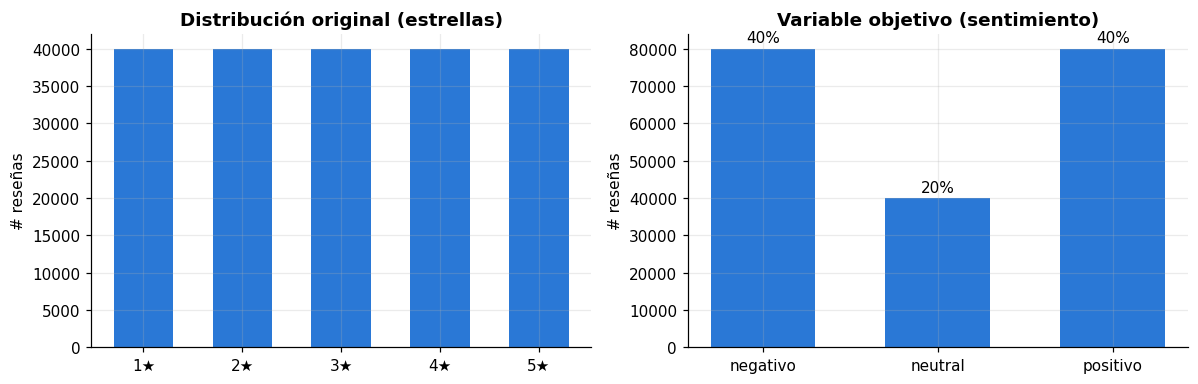

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
star_counts = df_tr["estrellas"].value_counts().sort_index()
axes[0].bar(star_counts.index.astype(str) + "★", star_counts.values, color=COLORS[0], width=0.6)
axes[0].set(title="Distribución original (estrellas)", ylabel="# reseñas")

sent_counts = df_tr["sentimiento"].value_counts().reindex(CLS_LABELS)
bars = axes[1].bar(sent_counts.index, sent_counts.values, color=COLORS[0], width=0.6)
for b, v in zip(bars, sent_counts.values):
    axes[1].annotate(f"{v/len(df_tr):.0%}", (b.get_x() + b.get_width()/2, v),
                     textcoords="offset points", xytext=(0, 4), ha="center")
axes[1].set(title="Variable objetivo (sentimiento)", ylabel="# reseñas")
plt.tight_layout(); plt.show()

count    200000.0
mean         27.8
std          24.2
min           2.0
25%          13.0
50%          22.0
75%          34.0
max         551.0
Name: n_palabras, dtype: float64


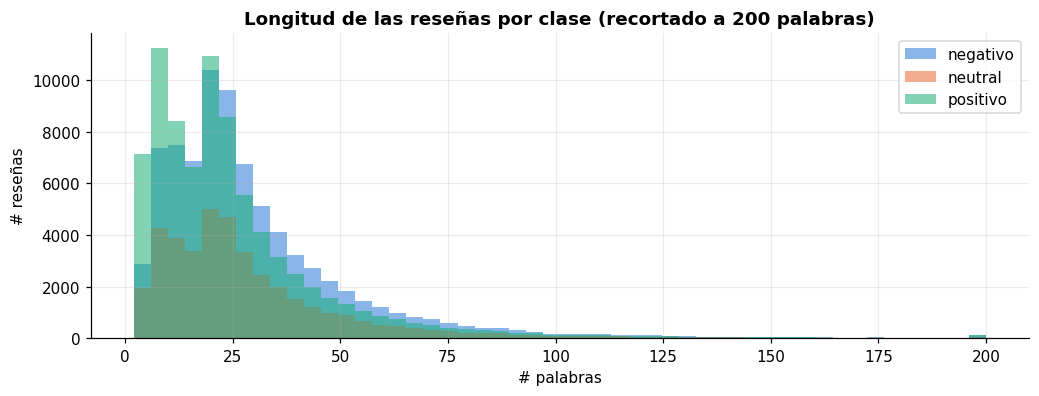

sentimiento
negativo    23.0
neutral     23.0
positivo    20.0
Name: mediana de palabras, dtype: float64


In [8]:
# Longitud de las reseñas en palabras
df_tr["n_palabras"] = df_tr["text"].str.split().str.len()
print(df_tr["n_palabras"].describe().round(1))

fig, ax = plt.subplots(figsize=(11, 3.6))
for i, lab in enumerate(CLS_LABELS):
    ax.hist(df_tr.loc[df_tr["sentimiento"] == lab, "n_palabras"].clip(upper=200), bins=50,
            alpha=0.55, color=COLORS[i], label=lab)
ax.set(title="Longitud de las reseñas por clase (recortado a 200 palabras)", xlabel="# palabras", ylabel="# reseñas")
ax.legend(); plt.show()

print(df_tr.groupby("sentimiento")["n_palabras"].median().rename("mediana de palabras"))

In [9]:
# Longitud en *tokens* de BETO: define el max_length de la tokenización
tok_cls = AutoTokenizer.from_pretrained(CLS_CHECKPOINT)
sample_texts = df_tr["text"].sample(5000, random_state=SEED).tolist()
tok_lens = np.array([len(ids) for ids in tok_cls(sample_texts)["input_ids"]])
for p in [50, 90, 95, 99]:
    print(f"Percentil {p}: {np.percentile(tok_lens, p):.0f} tokens")
print(f"Reseñas que caben en 128 tokens: {(tok_lens <= 128).mean():.1%}")

config.json:   0%|          | 0.00/648 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/364 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/242k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/480k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/134 [00:00<?, ?B/s]

Percentil 50: 29 tokens
Percentil 90: 70 tokens
Percentil 95: 90 tokens
Percentil 99: 153 tokens
Reseñas que caben en 128 tokens: 98.1%


Ejemplos de cada clase, para entender el problema:

In [10]:
for lab in CLS_LABELS:
    print(f"\n==================== {lab.upper()} ====================")
    for _, row in df_tr[df_tr["sentimiento"] == lab].sample(2, random_state=1).iterrows():
        print(f"[{row['estrellas']}★] {wrap(row['text'])}\n")


==================== NEGATIVO ====================
[1★] hola creo que en la publicidad la imagen que se muestra las miles de luces, pues es por lo que me anime pero
en las fichas no vienen en ninguno de los dos focos que yo compre por eso creo que esto no esta bien. un
saludo

[2★] No funciona con el móvil el protector y otro llego extropeado, nesecito la devolución del importe del pedido.
Gracias


==================== NEUTRAL ====================
[3★] El pelo me queda muy brillante y suelto. Pero a mi concretamente me pica mucho el cuero cabelludo cuando me
pongo este champu. Me irrita mucho y hasta que no me lavo con otro champú ese picor no se me pasa.

[3★] Con la gran extensión que abarca es normal que el detalle sea el justo. De español solo tiene la portada y
contraportada, difícil sacarle partido si no tiras de idiomas o imaginación. Para recorrer uno o dos países
del mapa mejor comprarlos por separado.


==================== POSITIVO ====================
[4★] De momento geni

**Observaciones del EDA**

- El conjunto es grande (200 000 reseñas) y está balanceado por estrellas. Tras el mapeo, la clase `neutral` es minoritaria (20 %), por eso se usa **F1 macro** como métrica principal.
- Las reseñas son cortas: mediana de **22 palabras** y **29 tokens**. El **98.1 %** cabe en **128 tokens**, así que truncar en esa longitud casi no pierde información y mantiene bajo el costo computacional.
- La longitud es casi igual entre clases (mediana de 20–23 palabras), así que el modelo no puede “hacer trampa” usando el largo del texto.
- Las reseñas de 3★ suelen mezclar aspectos positivos y negativos (“el pelo me queda muy brillante… pero me pica mucho el cuero cabelludo”), lo que anticipa que `neutral` será la clase más difícil.
- El texto es informal y con errores (“ka pantalla”, “nesecito”, “extropeado”). Se usa el modelo **cased** porque las mayúsculas pueden aportar intensidad emocional.
- Hay 1 736 textos duplicados en entrenamiento (0.9 %). Se dejan, porque su efecto es despreciable frente a 200 000 ejemplos.

## A.4 Preprocesamiento y tokenización

In [11]:
CLS_MAX_LEN = 128

def add_sentiment(batch):
    return {"labels": [stars_to_sentiment(l + 1) for l in batch["label"]]}

def tokenize_cls(batch):
    return tok_cls(batch["text"], truncation=True, max_length=CLS_MAX_LEN)

cls_ds = raw_cls.map(add_sentiment, batched=True)
cls_tok = cls_ds.map(tokenize_cls, batched=True,
                     remove_columns=[c for c in cls_ds["train"].column_names if c != "labels"])
cls_tok

Map:   0%|          | 0/200000 [00:00<?, ? examples/s]

Map:   0%|          | 0/5000 [00:00<?, ? examples/s]

Map:   0%|          | 0/5000 [00:00<?, ? examples/s]

Map:   0%|          | 0/200000 [00:00<?, ? examples/s]

Map:   0%|          | 0/5000 [00:00<?, ? examples/s]

Map:   0%|          | 0/5000 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['labels', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 200000
    })
    validation: Dataset({
        features: ['labels', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 5000
    })
    test: Dataset({
        features: ['labels', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 5000
    })
})

In [12]:
ex = cls_tok["train"][0]
print("Texto:", raw_cls["train"][0]["text"][:200])
print("Tokens:", tok_cls.convert_ids_to_tokens(ex["input_ids"])[:30])
print("Etiqueta:", ex["labels"], "→", CLS_LABELS[ex["labels"]])

Texto: Nada bueno se me fue ka pantalla en menos de 8 meses y no he recibido respuesta del fabricante
Tokens: ['[CLS]', 'Nada', 'bueno', 'se', 'me', 'fue', 'k', '##a', 'pantalla', 'en', 'menos', 'de', '8', 'meses', 'y', 'no', 'he', 'recibido', 'respuesta', 'del', 'fabricante', '[SEP]']
Etiqueta: 0 → negativo


## A.5 Funciones de entrenamiento y evaluación

In [13]:
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

id2label_cls = dict(enumerate(CLS_LABELS))
label2id_cls = {v: k for k, v in id2label_cls.items()}

def compute_metrics_cls(eval_pred):
    logits, labels = eval_pred
    if isinstance(logits, tuple):
        logits = logits[0]
    preds = np.argmax(logits, axis=-1)
    return {"accuracy": accuracy_score(labels, preds),
            "f1_macro": f1_score(labels, preds, average="macro")}

def train_cls(train_ds, eval_ds, lr, batch_size, epochs, output_dir, final=False, weight_decay=0.01):
    model = AutoModelForSequenceClassification.from_pretrained(
        CLS_CHECKPOINT, num_labels=len(CLS_LABELS), id2label=id2label_cls, label2id=label2id_cls)
    args = TrainingArguments(
        output_dir=output_dir,
        learning_rate=lr,
        per_device_train_batch_size=batch_size,
        per_device_eval_batch_size=128,
        num_train_epochs=epochs,
        weight_decay=weight_decay,
        warmup_steps=warmup_steps_for(len(train_ds), batch_size, epochs),
        lr_scheduler_type="linear",
        eval_strategy="epoch",
        save_strategy="epoch" if final else "no",
        load_best_model_at_end=final,
        metric_for_best_model="f1_macro",
        greater_is_better=True,
        save_total_limit=1,
        logging_steps=50,
        fp16=USE_FP16,
        report_to="none",
        seed=SEED,
    )
    trainer = Trainer(model=model, args=args, train_dataset=train_ds, eval_dataset=eval_ds,
                      processing_class=tok_cls, data_collator=DataCollatorWithPadding(tok_cls),
                      compute_metrics=compute_metrics_cls)
    t0 = time.time()
    trainer.train()
    elapsed = time.time() - t0
    metrics = trainer.evaluate()
    return trainer, metrics, elapsed

## A.6 Búsqueda de hiperparámetros sobre una muestra

Se entrena con una **muestra aleatoria de 8 000 reseñas** y se valida con 2 000, durante 2 épocas.

1. **Etapa 1 — learning rate:** se prueban los valores típicos recomendados para BERT: `1e-5, 2e-5, 3e-5, 5e-5`, con *batch size* 32.
2. **Etapa 2 — batch size:** con el mejor learning rate, se compara *batch size* 16 vs. 32.

Se escoge la configuración con mayor **F1 macro** en validación.

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  440MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

{'loss': '1.03', 'grad_norm': '3.748', 'learning_rate': '9.8e-06', 'epoch': '0.2'}
{'loss': '0.7401', 'grad_norm': '8.714', 'learning_rate': '8.911e-06', 'epoch': '0.4'}
{'loss': '0.6388', 'grad_norm': '6.503', 'learning_rate': '7.8e-06', 'epoch': '0.6'}
{'loss': '0.6413', 'grad_norm': '5.344', 'learning_rate': '6.689e-06', 'epoch': '0.8'}
{'loss': '0.6422', 'grad_norm': '4.84', 'learning_rate': '5.578e-06', 'epoch': '1'}
{'eval_loss': '0.5952', 'eval_accuracy': '0.75', 'eval_f1_macro': '0.6751', 'eval_runtime': '4.585', 'eval_samples_per_second': '436.2', 'eval_steps_per_second': '3.49', 'epoch': '1'}
{'loss': '0.5594', 'grad_norm': '6.573', 'learning_rate': '4.467e-06', 'epoch': '1.2'}
{'loss': '0.5562', 'grad_norm': '10.28', 'learning_rate': '3.356e-06', 'epoch': '1.4'}
{'loss': '0.5591', 'grad_norm': '7.302', 'learning_rate': '2.244e-06', 'epoch': '1.6'}
{'loss': '0.52', 'grad_norm': '7.506', 'learning_rate': '1.133e-06', 'epoch': '1.8'}
{'loss': '0.5512', 'grad_norm': '9.474', 'le

... (3 outputs left out)

{'loss': '0.947', 'grad_norm': 'inf', 'learning_rate': '2.94e-05', 'epoch': '0.2'}
{'loss': '0.686', 'grad_norm': '7.828', 'learning_rate': '2.673e-05', 'epoch': '0.4'}
{'loss': '0.6375', 'grad_norm': '6.146', 'learning_rate': '2.34e-05', 'epoch': '0.6'}
{'loss': '0.637', 'grad_norm': '3.944', 'learning_rate': '2.007e-05', 'epoch': '0.8'}
{'loss': '0.6094', 'grad_norm': '4.497', 'learning_rate': '1.673e-05', 'epoch': '1'}
{'eval_loss': '0.5846', 'eval_accuracy': '0.7415', 'eval_f1_macro': '0.6777', 'eval_runtime': '3.607', 'eval_samples_per_second': '554.6', 'eval_steps_per_second': '4.436', 'epoch': '1'}
{'loss': '0.5', 'grad_norm': '4.686', 'learning_rate': '1.34e-05', 'epoch': '1.2'}
{'loss': '0.4882', 'grad_norm': '7.358', 'learning_rate': '1.007e-05', 'epoch': '1.4'}
{'loss': '0.4822', 'grad_norm': '5.198', 'learning_rate': '6.733e-06', 'epoch': '1.6'}
{'loss': '0.4466', 'grad_norm': '5.688', 'learning_rate': '3.4e-06', 'epoch': '1.8'}
{'loss': '0.4694', 'grad_norm': '6.77', 'lear

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

{'loss': '0.9199', 'grad_norm': '6.828', 'learning_rate': '4.9e-05', 'epoch': '0.2'}
{'loss': '0.6878', 'grad_norm': '5.806', 'learning_rate': '4.456e-05', 'epoch': '0.4'}
{'loss': '0.6557', 'grad_norm': '7.934', 'learning_rate': '3.9e-05', 'epoch': '0.6'}
{'loss': '0.6346', 'grad_norm': '3.866', 'learning_rate': '3.344e-05', 'epoch': '0.8'}
{'loss': '0.6222', 'grad_norm': '6.064', 'learning_rate': '2.789e-05', 'epoch': '1'}
{'eval_loss': '0.5772', 'eval_accuracy': '0.75', 'eval_f1_macro': '0.6965', 'eval_runtime': '3.346', 'eval_samples_per_second': '597.7', 'eval_steps_per_second': '4.781', 'epoch': '1'}
{'loss': '0.4782', 'grad_norm': '5.47', 'learning_rate': '2.233e-05', 'epoch': '1.2'}
{'loss': '0.4731', 'grad_norm': '4.669', 'learning_rate': '1.678e-05', 'epoch': '1.4'}
{'loss': '0.4606', 'grad_norm': '6.811', 'learning_rate': '1.122e-05', 'epoch': '1.6'}
{'loss': '0.4303', 'grad_norm': '4.89', 'learning_rate': '5.667e-06', 'epoch': '1.8'}
{'loss': '0.4482', 'grad_norm': '4.81', 

,learning_rate,batch_size,eval_loss,accuracy,f1_macro,tiempo_s
2,0.00003,32,0.582631,0.7610,0.708744,88
1,0.00002,32,0.578603,0.7570,0.703232,94
3,0.00005,32,0.586480,0.7565,0.702941,89
0,0.00001,32,0.589122,0.7530,0.687786,112


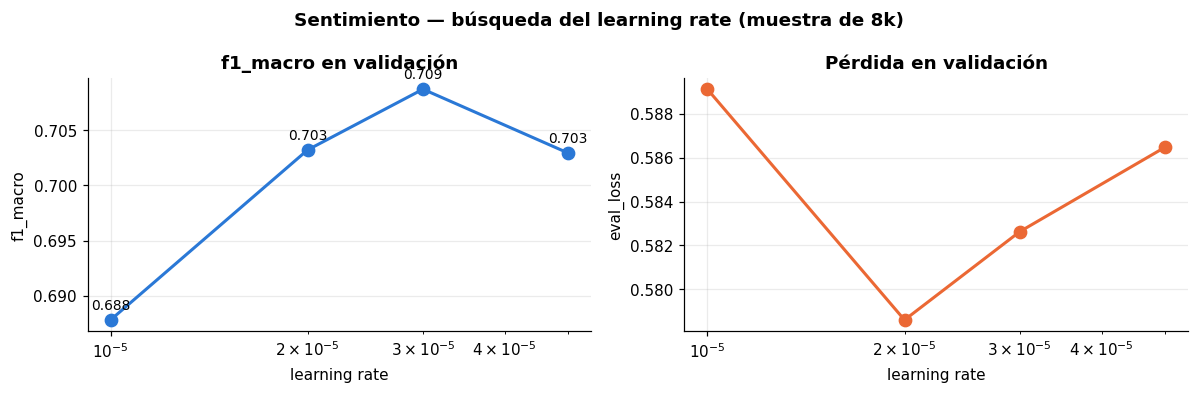

In [14]:
N_SEARCH_TRAIN_CLS = 8000
N_SEARCH_VAL_CLS = 2000
SEARCH_EPOCHS_CLS = 2
LR_GRID_CLS = [1e-5, 2e-5, 3e-5, 5e-5]

search_train_cls = cls_tok["train"].shuffle(seed=SEED).select(range(N_SEARCH_TRAIN_CLS))
search_val_cls = cls_tok["validation"].shuffle(seed=SEED).select(range(N_SEARCH_VAL_CLS))

search_cls = []
for lr in LR_GRID_CLS:
    trainer, m, t = train_cls(search_train_cls, search_val_cls, lr, 32, SEARCH_EPOCHS_CLS,
                              f"{OUT_DIR}/cls_search")
    search_cls.append({"learning_rate": lr, "batch_size": 32, "eval_loss": m["eval_loss"],
                       "accuracy": m["eval_accuracy"], "f1_macro": m["eval_f1_macro"], "tiempo_s": round(t)})
    print(search_cls[-1])
    del trainer; free_memory()

df_search_cls = pd.DataFrame(search_cls)
display(df_search_cls.sort_values("f1_macro", ascending=False))
plot_search(df_search_cls, "f1_macro", "Sentimiento — búsqueda del learning rate (muestra de 8k)")

In [15]:
# Etapa 2: batch size con el mejor learning rate
best_lr_cls = df_search_cls.loc[df_search_cls["f1_macro"].idxmax(), "learning_rate"]
trainer, m, t = train_cls(search_train_cls, search_val_cls, best_lr_cls, 16, SEARCH_EPOCHS_CLS,
                          f"{OUT_DIR}/cls_search")
search_cls.append({"learning_rate": best_lr_cls, "batch_size": 16, "eval_loss": m["eval_loss"],
                   "accuracy": m["eval_accuracy"], "f1_macro": m["eval_f1_macro"], "tiempo_s": round(t)})
del trainer; free_memory()

df_search_cls = pd.DataFrame(search_cls)
display(df_search_cls.sort_values("f1_macro", ascending=False))
best_cfg_cls = df_search_cls.loc[df_search_cls["f1_macro"].idxmax()]
BEST_LR_CLS, BEST_BS_CLS = float(best_cfg_cls["learning_rate"]), int(best_cfg_cls["batch_size"])
print(f"✅ Mejor configuración: learning_rate={BEST_LR_CLS}, batch_size={BEST_BS_CLS}, F1 macro={best_cfg_cls['f1_macro']:.4f}")

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

{'loss': '1.042', 'grad_norm': '4.894', 'learning_rate': '1.47e-05', 'epoch': '0.1'}
{'loss': '0.7576', 'grad_norm': '13.03', 'learning_rate': '2.97e-05', 'epoch': '0.2'}
{'loss': '0.6887', 'grad_norm': '8.252', 'learning_rate': '2.837e-05', 'epoch': '0.3'}
{'loss': '0.717', 'grad_norm': '6.403', 'learning_rate': '2.67e-05', 'epoch': '0.4'}
{'loss': '0.6429', 'grad_norm': '5.54', 'learning_rate': '2.503e-05', 'epoch': '0.5'}
{'loss': '0.647', 'grad_norm': '8.513', 'learning_rate': '2.337e-05', 'epoch': '0.6'}
{'loss': '0.576', 'grad_norm': '7.052', 'learning_rate': '2.17e-05', 'epoch': '0.7'}
{'loss': '0.6497', 'grad_norm': '6.485', 'learning_rate': '2.003e-05', 'epoch': '0.8'}
{'loss': '0.6349', 'grad_norm': '8.93', 'learning_rate': '1.837e-05', 'epoch': '0.9'}
{'loss': '0.6249', 'grad_norm': '10.14', 'learning_rate': '1.67e-05', 'epoch': '1'}
{'eval_loss': '0.5741', 'eval_accuracy': '0.7495', 'eval_f1_macro': '0.6812', 'eval_runtime': '3.643', 'eval_samples_per_second': '549', 'eval_

,learning_rate,batch_size,eval_loss,accuracy,f1_macro,tiempo_s
2,0.00003,32,0.582631,0.7610,0.708744,88
1,0.00002,32,0.578603,0.7570,0.703232,94
4,0.00003,16,0.588675,0.7545,0.703078,100
3,0.00005,32,0.586480,0.7565,0.702941,89
0,0.00001,32,0.589122,0.7530,0.687786,112


✅ Mejor configuración: learning_rate=3e-05, batch_size=32, F1 macro=0.7087


## A.7 Entrenamiento con la data completa

Se entrena con las **200 000 reseñas** y la mejor configuración. Se evalúa en el conjunto de validación completo al final de cada época y se conserva el mejor checkpoint.

In [16]:
N_TRAIN_FULL_CLS = None     # None = las 200 000 reseñas
EPOCHS_FULL_CLS = 2

full_train_cls = cls_tok["train"] if N_TRAIN_FULL_CLS is None else \
    cls_tok["train"].shuffle(seed=SEED).select(range(N_TRAIN_FULL_CLS))
print(f"Entrenando con {len(full_train_cls):,} reseñas | lr={BEST_LR_CLS} | batch={BEST_BS_CLS} | épocas={EPOCHS_FULL_CLS}")

trainer_cls, val_metrics_cls, time_cls = train_cls(
    full_train_cls, cls_tok["validation"], BEST_LR_CLS, BEST_BS_CLS, EPOCHS_FULL_CLS,
    f"{OUT_DIR}/cls_final", final=True)
print(f"Tiempo de entrenamiento: {time_cls/60:.1f} min")
print(val_metrics_cls)

Entrenando con 200,000 reseñas | lr=3e-05 | batch=32 | épocas=2


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

{'loss': '1.059', 'grad_norm': '3.055', 'learning_rate': '1.176e-06', 'epoch': '0.008'}
{'loss': '1.01', 'grad_norm': '3.719', 'learning_rate': '2.376e-06', 'epoch': '0.016'}
{'loss': '0.9164', 'grad_norm': '3.472', 'learning_rate': '3.576e-06', 'epoch': '0.024'}
{'loss': '0.7355', 'grad_norm': '4.844', 'learning_rate': '4.776e-06', 'epoch': '0.032'}
{'loss': '0.6724', 'grad_norm': '8.119', 'learning_rate': '5.976e-06', 'epoch': '0.04'}
{'loss': '0.6672', 'grad_norm': '6.145', 'learning_rate': '7.176e-06', 'epoch': '0.048'}
{'loss': '0.5882', 'grad_norm': '6.901', 'learning_rate': '8.376e-06', 'epoch': '0.056'}
{'loss': '0.6761', 'grad_norm': '6.828', 'learning_rate': '9.576e-06', 'epoch': '0.064'}
{'loss': '0.6132', 'grad_norm': '4.948', 'learning_rate': '1.078e-05', 'epoch': '0.072'}
{'loss': '0.6212', 'grad_norm': '6.545', 'learning_rate': '1.198e-05', 'epoch': '0.08'}
{'loss': '0.6286', 'grad_norm': '9.028', 'learning_rate': '1.318e-05', 'epoch': '0.088'}
{'loss': '0.6138', 'grad_n

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

{'loss': '0.4717', 'grad_norm': '4.558', 'learning_rate': '1.654e-05', 'epoch': '1.008'}
{'loss': '0.4925', 'grad_norm': '3.814', 'learning_rate': '1.64e-05', 'epoch': '1.016'}
{'loss': '0.4774', 'grad_norm': '2.831', 'learning_rate': '1.627e-05', 'epoch': '1.024'}
{'loss': '0.4724', 'grad_norm': '3.331', 'learning_rate': '1.614e-05', 'epoch': '1.032'}
{'loss': '0.4544', 'grad_norm': '3.531', 'learning_rate': '1.6e-05', 'epoch': '1.04'}
{'loss': '0.4615', 'grad_norm': '3.267', 'learning_rate': '1.587e-05', 'epoch': '1.048'}
{'loss': '0.4949', 'grad_norm': '3.352', 'learning_rate': '1.574e-05', 'epoch': '1.056'}
{'loss': '0.4864', 'grad_norm': '3.906', 'learning_rate': '1.56e-05', 'epoch': '1.064'}
{'loss': '0.4466', 'grad_norm': '6.219', 'learning_rate': '1.547e-05', 'epoch': '1.072'}
{'loss': '0.4867', 'grad_norm': '4.581', 'learning_rate': '1.534e-05', 'epoch': '1.08'}
{'loss': '0.4499', 'grad_norm': '4.831', 'learning_rate': '1.52e-05', 'epoch': '1.088'}
{'loss': '0.4982', 'grad_nor

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

{'train_runtime': '2089', 'train_samples_per_second': '191.5', 'train_steps_per_second': '5.984', 'train_loss': '0.5132', 'epoch': '2'}
{'eval_loss': '0.5285', 'eval_accuracy': '0.7806', 'eval_f1_macro': '0.726', 'eval_runtime': '8.109', 'eval_samples_per_second': '616.6', 'eval_steps_per_second': '4.933', 'epoch': '2'}
Tiempo de entrenamiento: 34.8 min
{'eval_loss': 0.5284752249717712, 'eval_accuracy': 0.7806, 'eval_f1_macro': 0.7259968596813726, 'eval_runtime': 8.1087, 'eval_samples_per_second': 616.624, 'eval_steps_per_second': 4.933, 'epoch': 2.0}


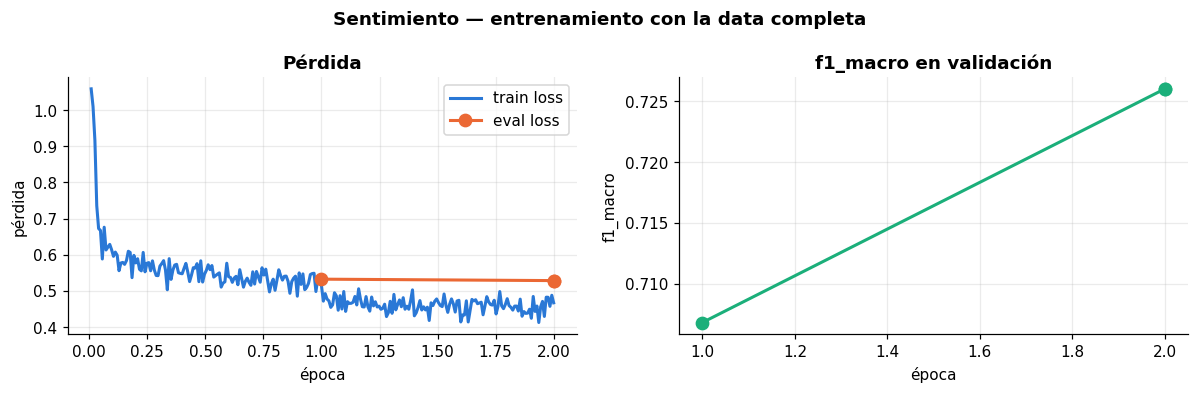

In [17]:
plot_history(trainer_cls, "f1_macro", "Sentimiento — entrenamiento con la data completa")

## A.8 Evaluación en el conjunto de prueba

In [18]:
pred_cls = trainer_cls.predict(cls_tok["test"])
y_true = pred_cls.label_ids
y_pred = pred_cls.predictions.argmax(-1)

majority = np.bincount(y_true).argmax()
print(f"Línea base (predecir siempre '{CLS_LABELS[majority]}'): accuracy = {(y_true == majority).mean():.4f}\n")
print(classification_report(y_true, y_pred, target_names=CLS_LABELS, digits=4))
test_acc_cls = accuracy_score(y_true, y_pred)
test_f1_cls = f1_score(y_true, y_pred, average="macro")

Línea base (predecir siempre 'negativo'): accuracy = 0.4000

              precision    recall  f1-score   support

    negativo     0.8232    0.8685    0.8453      2000
     neutral     0.5179    0.4490    0.4810      1000
    positivo     0.8710    0.8810    0.8760      2000

    accuracy                         0.7896      5000
   macro avg     0.7374    0.7328    0.7341      5000
weighted avg     0.7813    0.7896    0.7847      5000



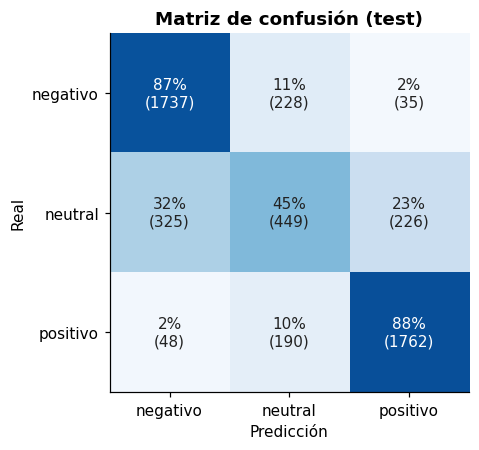

In [19]:
cm = confusion_matrix(y_true, y_pred)
cm_norm = cm / cm.sum(axis=1, keepdims=True)
fig, ax = plt.subplots(figsize=(5, 4.2))
ax.imshow(cm_norm, cmap="Blues", vmin=0, vmax=1)
ax.grid(False)
for i in range(len(CLS_LABELS)):
    for j in range(len(CLS_LABELS)):
        ax.text(j, i, f"{cm_norm[i, j]:.0%}\n({cm[i, j]})", ha="center", va="center",
                color="white" if cm_norm[i, j] > 0.5 else "#222")
ax.set_xticks(range(3), CLS_LABELS); ax.set_yticks(range(3), CLS_LABELS)
ax.set(xlabel="Predicción", ylabel="Real", title="Matriz de confusión (test)")
plt.tight_layout(); plt.show()

In [20]:
# Análisis de errores: ejemplos mal clasificados
df_test_cls = raw_cls["test"].to_pandas()
df_test_cls["real"] = [CLS_LABELS[i] for i in y_true]
df_test_cls["pred"] = [CLS_LABELS[i] for i in y_pred]
errores = df_test_cls[df_test_cls["real"] != df_test_cls["pred"]]
print(f"Errores: {len(errores)} de {len(df_test_cls)}\n")
for _, row in errores.sample(6, random_state=SEED).iterrows():
    print(f"Real: {row['real']:8s} | Predicho: {row['pred']:8s} | {row['label'] + 1}★\n{wrap(row['text'])}\n")

Errores: 1052 de 5000

Real: negativo | Predicho: neutral  | 2★
Los acabados no son tan buenos como esperaba. El espejo venia un poco rayado. Defrauda un poco cuando lo ves
en vivo.

Real: neutral  | Predicho: positivo | 3★
Perfecto para un perro de tamaño mediano como un beagle al mío le viene muy bien relación espacio y comodidad

Real: neutral  | Predicho: negativo | 3★
no es un mal objetivo, sinceramente elegí éste porque me llamó la atención su tamaño, no obstante es incluso
demasiado pequeño, tiene enfoque muy incomodo porque es con palanca no anillo, y MUY oscuro.

Real: neutral  | Predicho: positivo | 3★
Buenos guantes, calentitos, quizás un poco pequeños, pero yo tengo manos grandes. Al quedarme pequeños y
estirarlos un poco, se ha roto el encaje.

Real: neutral  | Predicho: negativo | 3★
La portería está bien pero solo para jugar con el balón de espuma niños pequeños xq la Red es muy endeble y
está todo el rato en el suelo.

Real: neutral  | Predicho: negativo | 3★
No se me r

## A.9 Mejor modelo: guardado y demostración

In [21]:
FINAL_CLS_DIR = os.path.join(BASE_DIR, "beto-sentimiento-amazon-es")
trainer_cls.save_model(FINAL_CLS_DIR)

save_result("A_sentimiento", {
    "dataset": CLS_DATASET, "modelo_base": CLS_CHECKPOINT,
    "learning_rate": BEST_LR_CLS, "batch_size": BEST_BS_CLS, "epocas": EPOCHS_FULL_CLS,
    "n_train": len(full_train_cls), "tiempo_min": round(time_cls / 60, 1),
    "test_accuracy": round(float(test_acc_cls), 4), "test_f1_macro": round(float(test_f1_cls), 4),
    "busqueda": df_search_cls.to_dict(orient="records"),
})

clf = pipeline("text-classification", model=FINAL_CLS_DIR, device=0 if DEVICE == "cuda" else -1)
ejemplos = [
    "Llegó rapidísimo y la calidad es excelente, súper recomendado.",
    "El producto está bien, cumple, aunque esperaba un poco más por el precio.",
    "Una porquería, se dañó a los dos días y nadie responde los reclamos.",
    "No está mal, pero las instrucciones vienen solo en inglés.",
]
for texto, pred in zip(ejemplos, clf(ejemplos)):
    print(f"{pred['label']:9s} ({pred['score']:.2f}) ← {texto}")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

positivo  (0.99) ← Llegó rapidísimo y la calidad es excelente, súper recomendado.
neutral   (0.60) ← El producto está bien, cumple, aunque esperaba un poco más por el precio.
negativo  (0.99) ← Una porquería, se dañó a los dos días y nadie responde los reclamos.
neutral   (0.62) ← No está mal, pero las instrucciones vienen solo en inglés.


### Conclusiones y análisis de resultados — Parte A (Sentimiento)

1. **Mejora frente a la línea base:**
   - La línea base que predice siempre la clase mayoritaria obtiene un *accuracy* de **40.00 %**.
   - BETO ajustado con las 200 000 reseñas durante 2 épocas (34.8 min en una T4) alcanza en test un **accuracy de 78.96 %** (+38.96 pp), un **F1 macro de 0.7341** y un F1 ponderado de 0.7847.

2. **Búsqueda de hiperparámetros (muestra de 8 000 reseñas):**
   - El mejor valor fue **learning rate = $3 \times 10^{-5}$** con **batch size = 32**: F1 macro de 0.7087 en validación, frente a 0.6878 con $1 \times 10^{-5}$, 0.7032 con $2 \times 10^{-5}$ y 0.7029 con $5 \times 10^{-5}$.
   - $1 \times 10^{-5}$ fue claramente el peor: con solo 2 épocas no alcanza a adaptar el modelo. Entre $2 \times 10^{-5}$ y $5 \times 10^{-5}$ las diferencias son de menos de 0.6 puntos, del mismo orden que la variación entre corridas, así que la región buena es amplia y no un punto exacto.
   - La pérdida de validación fue mínima con $2 \times 10^{-5}$, pero se eligió por F1 macro, que es la métrica de interés.
   - Con batch 16 el F1 fue prácticamente igual (0.7031 vs. 0.7087), y batch 32 fue algo más rápido (88 s vs. 100 s).

3. **Desempeño por clase:**
   - **Positivo:** precisión 0.8710, recall 0.8810, **F1 0.8760**.
   - **Negativo:** precisión 0.8232, recall 0.8685, **F1 0.8453**.
   - **Neutral:** precisión 0.5179, recall 0.4490, **F1 0.4810**.
   - Las clases polares superan 0.84 de F1, mientras `neutral` se queda en 0.48: esa clase explica casi toda la brecha entre *accuracy* y F1 macro.

4. **Entrenamiento completo:** el F1 macro de validación subió de 0.7068 en la época 1 a 0.7260 en la época 2, con la pérdida de validación estable (0.533 → 0.529): no hay señales de sobreajuste. Pasar de la muestra de 8 000 reseñas a las 200 000 subió el F1 macro de ~0.71 a ~0.73.

5. **Análisis de errores:**
   - Hubo 1 052 errores en las 5 000 reseñas de prueba (21.0 %). Según la matriz de confusión, **el 92 % involucra a la clase `neutral`**: solo 35 negativas se predijeron como positivas y 48 positivas como negativas.
   - La mayor confusión es neutral → negativo (325 casos, 32 % de las neutrales): las reseñas de 3★ suelen contener una queja concreta.
   - Varios errores son **ruido en la etiqueta**, no del modelo. Por ejemplo, “Perfecto para un perro de tamaño mediano… le viene muy bien” tiene 3★, pero el texto es claramente positivo, y el modelo lo predijo así. La etiqueta viene de las estrellas que dio el usuario, no de una anotación del texto.
   - En la demostración, el modelo clasifica bien frases nuevas, y marca como `neutral`, con menor confianza (0.60–0.62), las que mezclan algo positivo y algo negativo.

---
# Parte B — Etiquetado de secuencias: reconocimiento de entidades nombradas (NER) en español

## B.1 Descripción de la base de datos

**Base de datos:** CoNLL-2002, partición en español, tarea compartida de la *Conference on Computational Natural Language Learning*. Se usa la copia en formato Parquet [`BramVanroy/conll2002`](https://huggingface.co/datasets/BramVanroy/conll2002), configuración `es` (la versión original `conll2002` dependía de un *script* de carga que las versiones recientes de 🤗 `datasets` ya no ejecutan).

| Aspecto | Descripción |
|---|---|
| **Dominio** | Periodismo. Noticias de la agencia española **EFE** de mayo del año 2000. |
| **Utilidad** | La NER es un componente base de la extracción de información: indexar noticias por personas/organizaciones/lugares, anonimizar documentos (datos personales), construir grafos de conocimiento, mejorar buscadores y sistemas de pregunta-respuesta, análisis de documentos legales o clínicos. |
| **Datos de entrada** | `tokens`: una oración ya separada en palabras (lista de *tokens*). |
| **Variable de salida** | `ner_tags`: **una etiqueta por cada token**, en esquema **BIO/IOB2** con 4 tipos de entidad: `PER` (personas), `ORG` (organizaciones), `LOC` (lugares), `MISC` (otras: eventos, obras, nacionalidades…). `B-` marca el inicio de una entidad, `I-` su continuación y `O` los tokens fuera de entidades → 9 clases. |
| **Tipo de problema** | Etiquetado de secuencias (*token classification*): clasificación multiclase **de cada token**, donde la etiqueta depende del contexto. |
| **Tamaño** | 8 324 oraciones de entrenamiento, 1 916 de validación y 1 518 de prueba. |
| **Métrica** | **F1 a nivel de entidad** con `seqeval` (estándar de CoNLL): una entidad cuenta como correcta solo si su tipo **y** todos sus límites coinciden exactamente. |

> El dataset también trae etiquetas de *Part-of-Speech* (`pos_tags`), que no se usan aquí.

**Modelo:** BETO (`dccuchile/bert-base-spanish-wwm-cased`) con una cabeza lineal de clasificación sobre **cada** token de salida. Al ser *cased*, conserva las mayúsculas, que son una señal muy fuerte para detectar nombres propios.

## B.2 Carga de datos

In [22]:
NER_DATASET, NER_CONFIG = "BramVanroy/conll2002", "es"
NER_CHECKPOINT = "dccuchile/bert-base-spanish-wwm-cased"

raw_ner = load_dataset(NER_DATASET, NER_CONFIG)
try:
    NER_LABELS = list(raw_ner["train"].features["ner_tags"].feature.names)
except (AttributeError, KeyError):
    # Mapeo oficial de CoNLL-2002 (cuando la columna viene como enteros sin nombres)
    NER_LABELS = ["O", "B-PER", "I-PER", "B-ORG", "I-ORG", "B-LOC", "I-LOC", "B-MISC", "I-MISC"]
id2label_ner = dict(enumerate(NER_LABELS))
label2id_ner = {v: k for k, v in id2label_ner.items()}
print(raw_ner)
print("Etiquetas:", NER_LABELS)

README.md:   0%|          | 0.00/13.5k [00:00<?, ?B/s]

es/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.20MB            

es/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

es/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  250kB            

es/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

es/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  237kB            

es/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/8324 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/1916 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/1518 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['id', 'tokens', 'pos_tags', 'ner_tags'],
        num_rows: 8324
    })
    validation: Dataset({
        features: ['id', 'tokens', 'pos_tags', 'ner_tags'],
        num_rows: 1916
    })
    test: Dataset({
        features: ['id', 'tokens', 'pos_tags', 'ner_tags'],
        num_rows: 1518
    })
})
Etiquetas: ['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC', 'B-MISC', 'I-MISC']


## B.3 Análisis exploratorio de datos (EDA)

In [23]:
def show_sentence(tokens, tags):
    # Tabla token/etiqueta para una oración.
    return pd.DataFrame({"token": tokens, "etiqueta": [NER_LABELS[t] for t in tags]}).T

def extract_entities(tokens, tags):
    # Convierte la secuencia BIO en una lista de (tipo, texto).
    ents, cur_type, cur_toks = [], None, []
    for tok, t in zip(tokens, tags):
        lab = NER_LABELS[t]
        if lab.startswith("B-") or (lab.startswith("I-") and lab[2:] != cur_type):
            if cur_type: ents.append((cur_type, " ".join(cur_toks)))
            cur_type, cur_toks = lab[2:], [tok]
        elif lab.startswith("I-"):
            cur_toks.append(tok)
        else:
            if cur_type: ents.append((cur_type, " ".join(cur_toks)))
            cur_type, cur_toks = None, []
    if cur_type: ents.append((cur_type, " ".join(cur_toks)))
    return ents

def highlight(tokens, tags):
    # Oración con las entidades marcadas entre corchetes.
    out, i = [], 0
    labs = [NER_LABELS[t] for t in tags]
    while i < len(tokens):
        if labs[i] != "O":
            typ, span = labs[i][2:], [tokens[i]]
            i += 1
            while i < len(tokens) and labs[i] == f"I-{typ}":
                span.append(tokens[i]); i += 1
            out.append(f"[{' '.join(span)}]({typ})")
        else:
            out.append(tokens[i]); i += 1
    return " ".join(out)

for idx in [0, 3, 12]:
    ex = raw_ner["train"][idx]
    print(highlight(ex["tokens"], ex["ner_tags"]))
display(show_sentence(raw_ner["train"][3]["tokens"], raw_ner["train"][3]["ner_tags"]))

[Melbourne](LOC) ( [Australia](LOC) ) , 25 may ( [EFE](ORG) ) .
La petición del [Abogado General](PER) tiene lugar después de que un juez del [Tribunal Supremo](ORG) del estado de [Victoria](LOC) ( [Australia](LOC) ) se viera forzado a disolver un jurado popular y suspender el proceso ante el argumento de la defensa de que las personas que lo componían podían haber obtenido información sobre el acusado a través de la página [CrimeNet](MISC) .
[Gómez de la Hera](PER) comentó que los contenidos de la publicación " [Ciudad](MISC) " responden al programa que él encabezó como candidato en las elecciones municipales de 1999 , en las que [IU](ORG) perdió su representación en el [Ayuntamiento](ORG) , y confió en que su difusión sea más amplia una vez que la coalición resuelva su crisis económica .


,0,1,2,3,4,5,6,7,8,9,...,51,52,53,54,55,56,57,58,59,60
token,La,petición,del,Abogado,General,tiene,lugar,después,de,que,...,sobre,el,acusado,a,través,de,la,página,CrimeNet,.
etiqueta,O,O,O,B-PER,I-PER,O,O,O,O,O,...,O,O,O,O,O,O,O,O,B-MISC,O


,oraciones,tokens,ent. PER,ent. ORG,ent. LOC,ent. MISC,% tokens 'O'
partición,,,,,,,
train,8324,264715,4321,7390,4913,2173,87.6
validation,1916,52923,1222,1700,984,445,85.7
test,1518,51533,735,1400,1084,339,88.0


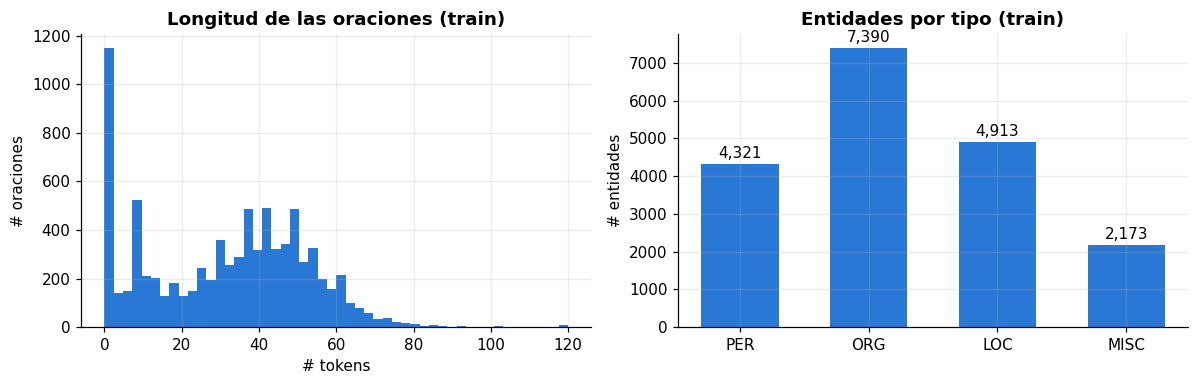

Longitud media: 31.8 tokens | máxima: 1238


In [24]:
rows = []
for split in raw_ner:
    tags_flat = [t for seq in raw_ner[split]["ner_tags"] for t in seq]
    c = Counter(NER_LABELS[t] for t in tags_flat)
    rows.append({"partición": split, "oraciones": len(raw_ner[split]), "tokens": len(tags_flat),
                 **{f"ent. {e}": c[f"B-{e}"] for e in ["PER", "ORG", "LOC", "MISC"]},
                 "% tokens 'O'": round(100 * c["O"] / len(tags_flat), 1)})
display(pd.DataFrame(rows).set_index("partición"))

sent_lens = [len(t) for t in raw_ner["train"]["tokens"]]
train_tags = Counter(NER_LABELS[t] for seq in raw_ner["train"]["ner_tags"] for t in seq)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].hist(np.clip(sent_lens, 0, 120), bins=50, color=COLORS[0])
axes[0].set(title="Longitud de las oraciones (train)", xlabel="# tokens", ylabel="# oraciones")
ent_types = ["PER", "ORG", "LOC", "MISC"]
vals = [train_tags[f"B-{e}"] for e in ent_types]
axes[1].bar(ent_types, vals, color=COLORS[0], width=0.6)
for i, v in enumerate(vals):
    axes[1].annotate(f"{v:,}", (i, v), textcoords="offset points", xytext=(0, 4), ha="center")
axes[1].set(title="Entidades por tipo (train)", ylabel="# entidades")
plt.tight_layout(); plt.show()
print(f"Longitud media: {np.mean(sent_lens):.1f} tokens | máxima: {max(sent_lens)}")

In [25]:
# Entidades más frecuentes por tipo
all_ents = [e for ex in raw_ner["train"] for e in extract_entities(ex["tokens"], ex["ner_tags"])]
top = {typ: [f"{txt} ({n})" for txt, n in Counter(t for ty, t in all_ents if ty == typ).most_common(8)]
       for typ in ent_types}
display(pd.DataFrame(top))

,PER,ORG,LOC,MISC
0,Reyes (25),EFE (905),Madrid (221),Liga de Campeones (35)
1,Aznar (22),Gobierno (237),España (147),Internet (33)
2,José María Aznar (19),PP (152),Barcelona (99),Interior (33)
3,Sanz (19),EFECOM (85),París (97),Cultura (18)
4,Chirac (16),UE (77),Francia (58),Medio Ambiente (18)
5,Corín Tellado (16),Real Madrid (73),Líbano (47),Agricultura (15)
6,Jospin (13),Efe (70),Badajoz (43),Educación (13)
7,Mariano Rajoy (12),Valencia (67),Santander (40),Exteriores (12)


**Observaciones del EDA**

- El **87.6 %** de los tokens de entrenamiento tiene la etiqueta `O`: el problema está muy desbalanceado a nivel de token, por eso la *accuracy* por token es engañosa y se usa el **F1 por entidad**.
- `ORG` es el tipo más frecuente (7 390 entidades en train: gobiernos, partidos, la propia agencia EFE, que aparece 905 veces). `MISC` es el menos frecuente (2 173) y el más heterogéneo: incluye eventos (“Liga de Campeones”) y también áreas de gobierno como “Interior” o “Cultura”. Por eso se espera que sea el más difícil.
- Hay ambigüedad real: “Valencia” aparece entre las `ORG` más frecuentes (equipo o institución), aunque también es una ciudad; “Madrid” es `LOC`, pero “Real Madrid” es `ORG`. Solo el contexto lo resuelve, que es justo lo que aporta un modelo contextual como BERT.
- Las oraciones miden 31.8 tokens en promedio, pero hay casos extremos (hasta 1 238). Con `max_length=256` subtokens se trunca solo una fracción mínima: el percentil 95 es de 74 subtokens.

## B.4 Tokenización y alineación de etiquetas

BETO usa *WordPiece*, por lo que una palabra puede dividirse en varios *subtokens*. Se asigna la etiqueta de la palabra **solo al primer subtoken** y `-100` (ignorado por la función de pérdida) a los demás subtokens y a los tokens especiales `[CLS]`/`[SEP]`.

In [26]:
NER_MAX_LEN = 256
tok_ner = AutoTokenizer.from_pretrained(NER_CHECKPOINT)
assert tok_ner.is_fast, "Se necesita un tokenizador 'fast' para usar word_ids()"

def tokenize_and_align(batch):
    enc = tok_ner(batch["tokens"], is_split_into_words=True, truncation=True, max_length=NER_MAX_LEN)
    all_labels = []
    for i, tags in enumerate(batch["ner_tags"]):
        prev, labels = None, []
        for w in enc.word_ids(batch_index=i):
            if w is None or w == prev:
                labels.append(-100)
            else:
                labels.append(tags[w])
            prev = w
        all_labels.append(labels)
    enc["labels"] = all_labels
    return enc

ner_tok = raw_ner.map(tokenize_and_align, batched=True, remove_columns=raw_ner["train"].column_names)

# Visualizar la alineación en un ejemplo
ex_tok = ner_tok["train"][3]
display(pd.DataFrame({
    "subtoken": tok_ner.convert_ids_to_tokens(ex_tok["input_ids"]),
    "etiqueta": [NER_LABELS[l] if l != -100 else "-100" for l in ex_tok["labels"]],
}).T)
lens = [len(x) for x in ner_tok["train"]["input_ids"]]
print(f"Subtokens por oración — p95: {np.percentile(lens, 95):.0f}, máx: {max(lens)}")

Map:   0%|          | 0/8324 [00:00<?, ? examples/s]

Map:   0%|          | 0/1916 [00:00<?, ? examples/s]

Map:   0%|          | 0/1518 [00:00<?, ? examples/s]

,0,1,2,3,4,5,6,7,8,9,...,57,58,59,60,61,62,63,64,65,66
subtoken,[CLS],La,petición,del,Abogado,General,tiene,lugar,después,de,...,través,de,la,página,Cri,##me,##N,##et,.,[SEP]
etiqueta,-100,O,O,O,B-PER,I-PER,O,O,O,O,...,O,O,O,O,B-MISC,-100,-100,-100,O,-100


Subtokens por oración — p95: 74, máx: 256


## B.5 Funciones de entrenamiento y evaluación

In [27]:
from seqeval.metrics import classification_report as seq_report, f1_score as seq_f1, \
    precision_score as seq_precision, recall_score as seq_recall

def align_predictions(predictions, label_ids):
    preds = np.argmax(predictions, axis=-1)
    true_seqs, pred_seqs = [], []
    for p_row, l_row in zip(preds, label_ids):
        t, p = [], []
        for p_i, l_i in zip(p_row, l_row):
            if l_i != -100:
                t.append(NER_LABELS[l_i]); p.append(NER_LABELS[p_i])
        true_seqs.append(t); pred_seqs.append(p)
    return true_seqs, pred_seqs

def compute_metrics_ner(eval_pred):
    predictions, labels = eval_pred
    if isinstance(predictions, tuple):
        predictions = predictions[0]
    y_true, y_pred = align_predictions(predictions, labels)
    return {"precision": seq_precision(y_true, y_pred), "recall": seq_recall(y_true, y_pred),
            "f1": seq_f1(y_true, y_pred)}

def train_ner(train_ds, eval_ds, lr, batch_size, epochs, output_dir, final=False, weight_decay=0.01):
    model = AutoModelForTokenClassification.from_pretrained(
        NER_CHECKPOINT, num_labels=len(NER_LABELS), id2label=id2label_ner, label2id=label2id_ner)
    args = TrainingArguments(
        output_dir=output_dir,
        learning_rate=lr,
        per_device_train_batch_size=batch_size,
        per_device_eval_batch_size=64,
        num_train_epochs=epochs,
        weight_decay=weight_decay,
        warmup_steps=warmup_steps_for(len(train_ds), batch_size, epochs),
        eval_strategy="epoch",
        save_strategy="epoch" if final else "no",
        load_best_model_at_end=final,
        metric_for_best_model="f1",
        greater_is_better=True,
        save_total_limit=1,
        logging_steps=25,
        fp16=USE_FP16,
        report_to="none",
        seed=SEED,
    )
    trainer = Trainer(model=model, args=args, train_dataset=train_ds, eval_dataset=eval_ds,
                      processing_class=tok_ner, data_collator=DataCollatorForTokenClassification(tok_ner),
                      compute_metrics=compute_metrics_ner)
    t0 = time.time()
    trainer.train()
    elapsed = time.time() - t0
    return trainer, trainer.evaluate(), elapsed

## B.6 Búsqueda de hiperparámetros sobre una muestra

Muestra de **3 000 oraciones** de entrenamiento (≈36 %), validación completa (1 916), 3 épocas.

1. **Learning rate:** `2e-5, 3e-5, 5e-5, 8e-5` con *batch size* 16.
2. **Batch size:** con el mejor LR, 16 vs. 32.

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

{'loss': '1.945', 'grad_norm': '8.863', 'learning_rate': '8.571e-06', 'epoch': '0.133'}
{'loss': '0.6085', 'grad_norm': '1.231', 'learning_rate': '1.75e-05', 'epoch': '0.266'}
{'loss': '0.2423', 'grad_norm': '2.636', 'learning_rate': '1.929e-05', 'epoch': '0.3989'}
{'loss': '0.1296', 'grad_norm': '1.033', 'learning_rate': '1.831e-05', 'epoch': '0.5319'}
{'loss': '0.09177', 'grad_norm': '1.407', 'learning_rate': '1.732e-05', 'epoch': '0.6649'}
{'loss': '0.09256', 'grad_norm': '0.8078', 'learning_rate': '1.634e-05', 'epoch': '0.7979'}
{'loss': '0.08685', 'grad_norm': '1.665', 'learning_rate': '1.535e-05', 'epoch': '0.9309'}
{'eval_loss': '0.09982', 'eval_precision': '0.7768', 'eval_recall': '0.7958', 'eval_f1': '0.7862', 'eval_runtime': '3.615', 'eval_samples_per_second': '529.9', 'eval_steps_per_second': '8.298', 'epoch': '1'}
{'loss': '0.07066', 'grad_norm': '1.392', 'learning_rate': '1.437e-05', 'epoch': '1.064'}
{'loss': '0.0566', 'grad_norm': '1.36', 'learning_rate': '1.339e-05', 'e

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

{'loss': '1.76', 'grad_norm': '2.565', 'learning_rate': '1.286e-05', 'epoch': '0.133'}
{'loss': '0.49', 'grad_norm': '1.772', 'learning_rate': '2.625e-05', 'epoch': '0.266'}
{'loss': '0.174', 'grad_norm': '1.797', 'learning_rate': '2.894e-05', 'epoch': '0.3989'}
{'loss': '0.1094', 'grad_norm': '1.062', 'learning_rate': '2.746e-05', 'epoch': '0.5319'}
{'loss': '0.07767', 'grad_norm': '1.156', 'learning_rate': '2.598e-05', 'epoch': '0.6649'}
{'loss': '0.08844', 'grad_norm': '0.6118', 'learning_rate': '2.451e-05', 'epoch': '0.7979'}
{'loss': '0.08024', 'grad_norm': '1.562', 'learning_rate': '2.303e-05', 'epoch': '0.9309'}
{'eval_loss': '0.09654', 'eval_precision': '0.774', 'eval_recall': '0.7988', 'eval_f1': '0.7862', 'eval_runtime': '3.175', 'eval_samples_per_second': '603.4', 'eval_steps_per_second': '9.448', 'epoch': '1'}
{'loss': '0.06355', 'grad_norm': '0.7504', 'learning_rate': '2.156e-05', 'epoch': '1.064'}
{'loss': '0.0512', 'grad_norm': '0.8756', 'learning_rate': '2.008e-05', 'ep

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

{'loss': '1.543', 'grad_norm': '2.846', 'learning_rate': '2.143e-05', 'epoch': '0.133'}
{'loss': '0.3695', 'grad_norm': '1.884', 'learning_rate': '4.375e-05', 'epoch': '0.266'}
{'loss': '0.1304', 'grad_norm': '1.952', 'learning_rate': '4.823e-05', 'epoch': '0.3989'}
{'loss': '0.1019', 'grad_norm': '1.915', 'learning_rate': '4.577e-05', 'epoch': '0.5319'}
{'loss': '0.0736', 'grad_norm': '1.841', 'learning_rate': '4.331e-05', 'epoch': '0.6649'}
{'loss': '0.09289', 'grad_norm': '0.5934', 'learning_rate': '4.085e-05', 'epoch': '0.7979'}
{'loss': '0.07801', 'grad_norm': '1.267', 'learning_rate': '3.839e-05', 'epoch': '0.9309'}
{'eval_loss': '0.0948', 'eval_precision': '0.778', 'eval_recall': '0.7995', 'eval_f1': '0.7886', 'eval_runtime': '3.381', 'eval_samples_per_second': '566.7', 'eval_steps_per_second': '8.874', 'epoch': '1'}
{'loss': '0.06124', 'grad_norm': '0.6042', 'learning_rate': '3.593e-05', 'epoch': '1.064'}
{'loss': '0.04619', 'grad_norm': '0.8922', 'learning_rate': '3.346e-05', 

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

{'loss': '1.369', 'grad_norm': '2.889', 'learning_rate': '3.429e-05', 'epoch': '0.133'}
{'loss': '0.2683', 'grad_norm': '1.981', 'learning_rate': '7e-05', 'epoch': '0.266'}
{'loss': '0.1167', 'grad_norm': '2.498', 'learning_rate': '7.717e-05', 'epoch': '0.3989'}
{'loss': '0.1047', 'grad_norm': '0.9192', 'learning_rate': '7.323e-05', 'epoch': '0.5319'}
{'loss': '0.07059', 'grad_norm': '1.9', 'learning_rate': '6.929e-05', 'epoch': '0.6649'}
{'loss': '0.08907', 'grad_norm': '0.5582', 'learning_rate': '6.535e-05', 'epoch': '0.7979'}
{'loss': '0.08026', 'grad_norm': '0.9141', 'learning_rate': '6.142e-05', 'epoch': '0.9309'}
{'eval_loss': '0.102', 'eval_precision': '0.7471', 'eval_recall': '0.7988', 'eval_f1': '0.7721', 'eval_runtime': '3.188', 'eval_samples_per_second': '600.9', 'eval_steps_per_second': '9.409', 'epoch': '1'}
{'loss': '0.05783', 'grad_norm': '0.4992', 'learning_rate': '5.748e-05', 'epoch': '1.064'}
{'loss': '0.04862', 'grad_norm': '1.132', 'learning_rate': '5.354e-05', 'epo

,learning_rate,batch_size,eval_loss,precision,recall,f1,tiempo_s
3,0.00008,16,0.093911,0.829984,0.847200,0.838504,58
1,0.00003,16,0.091397,0.814215,0.834294,0.824132,58
2,0.00005,16,0.095546,0.812008,0.832219,0.821990,58
0,0.00002,16,0.092647,0.809824,0.828301,0.818959,62


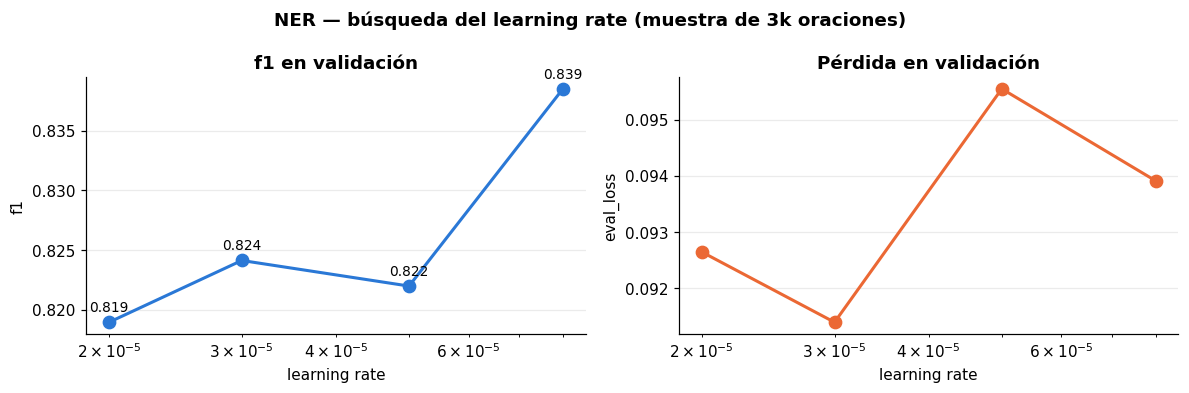

In [28]:
N_SEARCH_TRAIN_NER = 3000
SEARCH_EPOCHS_NER = 3
LR_GRID_NER = [2e-5, 3e-5, 5e-5, 8e-5]

search_train_ner = ner_tok["train"].shuffle(seed=SEED).select(range(N_SEARCH_TRAIN_NER))
search_ner = []
for lr in LR_GRID_NER:
    trainer, m, t = train_ner(search_train_ner, ner_tok["validation"], lr, 16, SEARCH_EPOCHS_NER,
                              f"{OUT_DIR}/ner_search")
    search_ner.append({"learning_rate": lr, "batch_size": 16, "eval_loss": m["eval_loss"],
                       "precision": m["eval_precision"], "recall": m["eval_recall"], "f1": m["eval_f1"],
                       "tiempo_s": round(t)})
    print(search_ner[-1])
    del trainer; free_memory()

df_search_ner = pd.DataFrame(search_ner)
display(df_search_ner.sort_values("f1", ascending=False))
plot_search(df_search_ner, "f1", "NER — búsqueda del learning rate (muestra de 3k oraciones)")

In [29]:
best_lr_ner = df_search_ner.loc[df_search_ner["f1"].idxmax(), "learning_rate"]
trainer, m, t = train_ner(search_train_ner, ner_tok["validation"], best_lr_ner, 32, SEARCH_EPOCHS_NER,
                          f"{OUT_DIR}/ner_search")
search_ner.append({"learning_rate": best_lr_ner, "batch_size": 32, "eval_loss": m["eval_loss"],
                   "precision": m["eval_precision"], "recall": m["eval_recall"], "f1": m["eval_f1"],
                   "tiempo_s": round(t)})
del trainer; free_memory()

df_search_ner = pd.DataFrame(search_ner)
display(df_search_ner.sort_values("f1", ascending=False))
best_cfg_ner = df_search_ner.loc[df_search_ner["f1"].idxmax()]
BEST_LR_NER, BEST_BS_NER = float(best_cfg_ner["learning_rate"]), int(best_cfg_ner["batch_size"])
print(f"✅ Mejor configuración: learning_rate={BEST_LR_NER}, batch_size={BEST_BS_NER}, F1={best_cfg_ner['f1']:.4f}")

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

{'loss': '1.13', 'grad_norm': '1.614', 'learning_rate': '6.857e-05', 'epoch': '0.266'}
{'loss': '0.1353', 'grad_norm': '0.9778', 'learning_rate': '7.339e-05', 'epoch': '0.5319'}
{'loss': '0.08196', 'grad_norm': '0.6586', 'learning_rate': '6.551e-05', 'epoch': '0.7979'}
{'eval_loss': '0.09696', 'eval_precision': '0.7655', 'eval_recall': '0.796', 'eval_f1': '0.7805', 'eval_runtime': '3.666', 'eval_samples_per_second': '522.7', 'eval_steps_per_second': '8.184', 'epoch': '1'}
{'loss': '0.07002', 'grad_norm': '0.7677', 'learning_rate': '5.764e-05', 'epoch': '1.064'}
{'loss': '0.04925', 'grad_norm': '0.8336', 'learning_rate': '4.976e-05', 'epoch': '1.33'}
{'loss': '0.04339', 'grad_norm': '0.4783', 'learning_rate': '4.189e-05', 'epoch': '1.596'}
{'loss': '0.03883', 'grad_norm': '1.063', 'learning_rate': '3.402e-05', 'epoch': '1.862'}
{'eval_loss': '0.0941', 'eval_precision': '0.8219', 'eval_recall': '0.8209', 'eval_f1': '0.8214', 'eval_runtime': '3.389', 'eval_samples_per_second': '565.4', 'e

,learning_rate,batch_size,eval_loss,precision,recall,f1,tiempo_s
3,0.00008,16,0.093911,0.829984,0.847200,0.838504,58
4,0.00008,32,0.089827,0.826047,0.836137,0.831062,51
1,0.00003,16,0.091397,0.814215,0.834294,0.824132,58
2,0.00005,16,0.095546,0.812008,0.832219,0.821990,58
0,0.00002,16,0.092647,0.809824,0.828301,0.818959,62


✅ Mejor configuración: learning_rate=8e-05, batch_size=16, F1=0.8385


## B.7 Entrenamiento con la data completa

El conjunto es pequeño, así que se usan **todas** las oraciones de entrenamiento y algunas épocas más.

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

{'loss': '2.017', 'grad_norm': '9.802', 'learning_rate': '7.385e-06', 'epoch': '0.04798'}
{'loss': '0.632', 'grad_norm': '1.822', 'learning_rate': '1.508e-05', 'epoch': '0.09597'}
{'loss': '0.3022', 'grad_norm': '2.21', 'learning_rate': '2.277e-05', 'epoch': '0.144'}
{'loss': '0.1504', 'grad_norm': '1.349', 'learning_rate': '3.046e-05', 'epoch': '0.1919'}
{'loss': '0.09758', 'grad_norm': '1.435', 'learning_rate': '3.815e-05', 'epoch': '0.2399'}
{'loss': '0.09498', 'grad_norm': '2.186', 'learning_rate': '4.585e-05', 'epoch': '0.2879'}
{'loss': '0.0818', 'grad_norm': '1.378', 'learning_rate': '5.354e-05', 'epoch': '0.3359'}
{'loss': '0.08659', 'grad_norm': '2.445', 'learning_rate': '6.123e-05', 'epoch': '0.3839'}
{'loss': '0.07941', 'grad_norm': '2.059', 'learning_rate': '6.892e-05', 'epoch': '0.4319'}
{'loss': '0.09017', 'grad_norm': '2.447', 'learning_rate': '7.662e-05', 'epoch': '0.4798'}
{'loss': '0.08245', 'grad_norm': '1.97', 'learning_rate': '7.952e-05', 'epoch': '0.5278'}
{'loss'

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

{'loss': '0.05217', 'grad_norm': '0.3024', 'learning_rate': '7.099e-05', 'epoch': '1.008'}
{'loss': '0.03336', 'grad_norm': '1.379', 'learning_rate': '7.014e-05', 'epoch': '1.056'}
{'loss': '0.05071', 'grad_norm': '1.282', 'learning_rate': '6.929e-05', 'epoch': '1.104'}
{'loss': '0.03948', 'grad_norm': '0.8976', 'learning_rate': '6.843e-05', 'epoch': '1.152'}
{'loss': '0.05179', 'grad_norm': '0.4272', 'learning_rate': '6.758e-05', 'epoch': '1.2'}
{'loss': '0.04584', 'grad_norm': '1.343', 'learning_rate': '6.673e-05', 'epoch': '1.248'}
{'loss': '0.04376', 'grad_norm': '0.4921', 'learning_rate': '6.588e-05', 'epoch': '1.296'}
{'loss': '0.03954', 'grad_norm': '1.276', 'learning_rate': '6.502e-05', 'epoch': '1.344'}
{'loss': '0.04029', 'grad_norm': '0.813', 'learning_rate': '6.417e-05', 'epoch': '1.392'}
{'loss': '0.03199', 'grad_norm': '1.332', 'learning_rate': '6.332e-05', 'epoch': '1.44'}
{'loss': '0.04424', 'grad_norm': '0.8962', 'learning_rate': '6.246e-05', 'epoch': '1.488'}
{'loss':

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

{'loss': '0.04297', 'grad_norm': '0.5392', 'learning_rate': '5.308e-05', 'epoch': '2.015'}
{'loss': '0.02017', 'grad_norm': '0.806', 'learning_rate': '5.223e-05', 'epoch': '2.063'}
{'loss': '0.02046', 'grad_norm': '0.6718', 'learning_rate': '5.138e-05', 'epoch': '2.111'}
{'loss': '0.01479', 'grad_norm': '0.5011', 'learning_rate': '5.052e-05', 'epoch': '2.159'}
{'loss': '0.01619', 'grad_norm': '1.734', 'learning_rate': '4.967e-05', 'epoch': '2.207'}
{'loss': '0.02349', 'grad_norm': '0.2477', 'learning_rate': '4.882e-05', 'epoch': '2.255'}
{'loss': '0.02782', 'grad_norm': '0.9745', 'learning_rate': '4.797e-05', 'epoch': '2.303'}
{'loss': '0.02229', 'grad_norm': '0.397', 'learning_rate': '4.711e-05', 'epoch': '2.351'}
{'loss': '0.02665', 'grad_norm': '0.845', 'learning_rate': '4.626e-05', 'epoch': '2.399'}
{'loss': '0.02323', 'grad_norm': '0.2888', 'learning_rate': '4.541e-05', 'epoch': '2.447'}
{'loss': '0.02246', 'grad_norm': '1.277', 'learning_rate': '4.455e-05', 'epoch': '2.495'}
{'lo

... (2 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

{'loss': '0.007266', 'grad_norm': '0.06079', 'learning_rate': '1.726e-05', 'epoch': '4.031'}
{'loss': '0.005226', 'grad_norm': '0.5386', 'learning_rate': '1.641e-05', 'epoch': '4.079'}
{'loss': '0.006189', 'grad_norm': '0.4946', 'learning_rate': '1.556e-05', 'epoch': '4.127'}
{'loss': '0.004475', 'grad_norm': '0.1066', 'learning_rate': '1.47e-05', 'epoch': '4.175'}
{'loss': '0.005029', 'grad_norm': '0.08636', 'learning_rate': '1.385e-05', 'epoch': '4.223'}
{'loss': '0.005653', 'grad_norm': '0.4751', 'learning_rate': '1.3e-05', 'epoch': '4.271'}
{'loss': '0.005546', 'grad_norm': '0.05142', 'learning_rate': '1.214e-05', 'epoch': '4.319'}
{'loss': '0.008085', 'grad_norm': '0.1432', 'learning_rate': '1.129e-05', 'epoch': '4.367'}
{'loss': '0.007285', 'grad_norm': '0.01846', 'learning_rate': '1.044e-05', 'epoch': '4.415'}
{'loss': '0.006843', 'grad_norm': '0.3142', 'learning_rate': '9.586e-06', 'epoch': '4.463'}
{'loss': '0.003144', 'grad_norm': '0.07904', 'learning_rate': '8.733e-06', 'epo

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

{'train_runtime': '295.6', 'train_samples_per_second': '140.8', 'train_steps_per_second': '8.814', 'train_loss': '0.05837', 'epoch': '5'}
{'eval_loss': '0.09137', 'eval_precision': '0.8492', 'eval_recall': '0.864', 'eval_f1': '0.8565', 'eval_runtime': '3.243', 'eval_samples_per_second': '590.9', 'eval_steps_per_second': '9.252', 'epoch': '5'}
Tiempo de entrenamiento: 5.0 min
{'eval_loss': 0.09137381613254547, 'eval_precision': 0.8491506228765572, 'eval_recall': 0.8640239686563724, 'eval_f1': 0.8565227324651586, 'eval_runtime': 3.2426, 'eval_samples_per_second': 590.893, 'eval_steps_per_second': 9.252, 'epoch': 5.0}


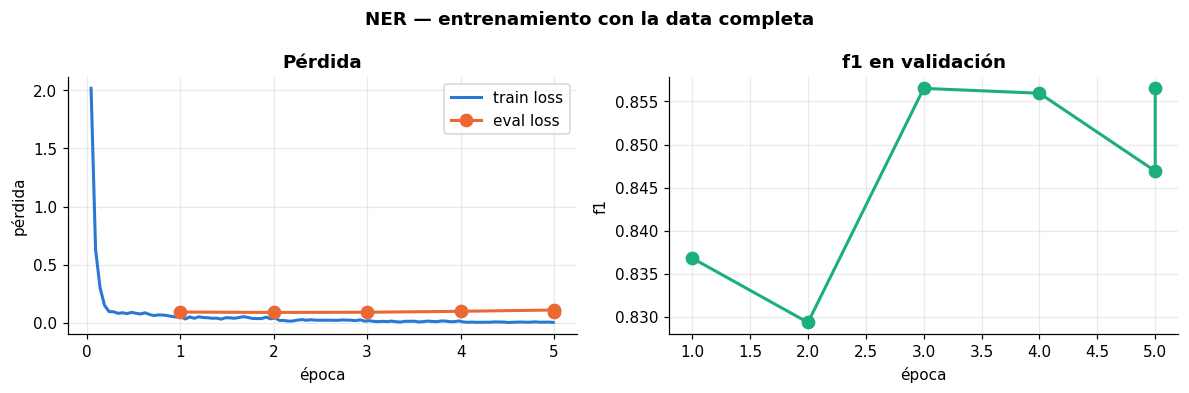

In [30]:
EPOCHS_FULL_NER = 5
trainer_ner, val_metrics_ner, time_ner = train_ner(
    ner_tok["train"], ner_tok["validation"], BEST_LR_NER, BEST_BS_NER, EPOCHS_FULL_NER,
    f"{OUT_DIR}/ner_final", final=True)
print(f"Tiempo de entrenamiento: {time_ner/60:.1f} min")
print(val_metrics_ner)
plot_history(trainer_ner, "f1", "NER — entrenamiento con la data completa")

## B.8 Evaluación en el conjunto de prueba

              precision    recall  f1-score   support

         LOC     0.8868    0.8105    0.8469      1082
        MISC     0.7788    0.7147    0.7454       340
         ORG     0.8132    0.9249    0.8655      1398
         PER     0.9519    0.9727    0.9622       732

   micro avg     0.8588    0.8798    0.8691      3552
   macro avg     0.8577    0.8557    0.8550      3552
weighted avg     0.8609    0.8798    0.8683      3552



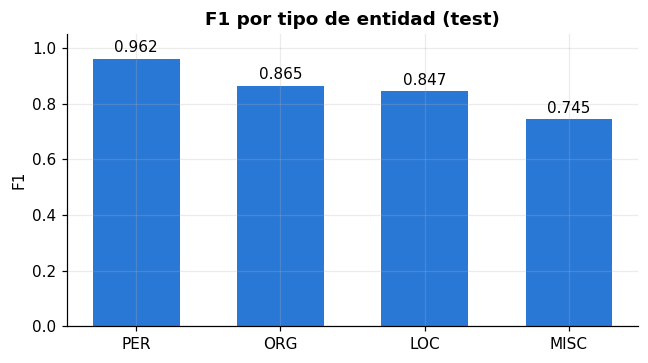

In [31]:
pred_ner = trainer_ner.predict(ner_tok["test"])
y_true_ner, y_pred_ner = align_predictions(pred_ner.predictions, pred_ner.label_ids)
print(seq_report(y_true_ner, y_pred_ner, digits=4))
test_f1_ner = seq_f1(y_true_ner, y_pred_ner)
test_p_ner, test_r_ner = seq_precision(y_true_ner, y_pred_ner), seq_recall(y_true_ner, y_pred_ner)

rep = seq_report(y_true_ner, y_pred_ner, output_dict=True)
f1_by_type = [rep[e]["f1-score"] for e in ent_types]
fig, ax = plt.subplots(figsize=(6, 3.4))
ax.bar(ent_types, f1_by_type, color=COLORS[0], width=0.6)
for i, v in enumerate(f1_by_type):
    ax.annotate(f"{v:.3f}", (i, v), textcoords="offset points", xytext=(0, 4), ha="center")
ax.set(ylim=(0, 1.05), ylabel="F1", title="F1 por tipo de entidad (test)")
plt.tight_layout(); plt.show()

In [32]:
# Análisis de errores: oraciones de test donde la predicción difiere de la referencia
shown = 0
for i, (t, p) in enumerate(zip(y_true_ner, y_pred_ner)):
    if t != p and shown < 4:
        toks = raw_ner["test"][i]["tokens"][:len(t)]
        print("REAL:", highlight(toks, [label2id_ner[x] for x in t]))
        print("PRED:", highlight(toks, [label2id_ner[x] for x in p]), "\n")
        shown += 1

REAL: Las reservas " on line " de billetes aéreos a través de [Internet](MISC) aumentaron en [España](LOC) un 300 por ciento en el primer trimestre de este año con respecto al mismo período de 1999 , aseguró hoy [Iñigo García Aranda](PER) , responsable de comunicación de [Savia Amadeus](ORG) .
PRED: Las reservas " on line " de billetes aéreos a través de [Internet](MISC) aumentaron en [España](LOC) un 300 por ciento en el primer trimestre de este año con respecto al mismo período de 1999 , aseguró hoy [Iñigo García Aranda](PER) , responsable de comunicación de [Savia Amadeus](PER) . 

REAL: Los clientes pueden utilizar el portal " [viajesydestinos.com](MISC) " , que el pasado año recibió ya más de medio millón de visitas de [Internautas](MISC) , para consultar tarifas de billetes de transporte , plazas hoteleras o paquetes turísticos , aunque la venta final corre siempre a cargo de una agencia de viajes , explicó el responsable de [Savia Amadeus](ORG) .
PRED: Los clientes pueden utiliz

## B.9 Mejor modelo: guardado y demostración

In [33]:
FINAL_NER_DIR = os.path.join(BASE_DIR, "beto-ner-conll2002-es")
trainer_ner.save_model(FINAL_NER_DIR)
save_result("B_ner", {
    "dataset": f"{NER_DATASET} ({NER_CONFIG})", "modelo_base": NER_CHECKPOINT,
    "learning_rate": BEST_LR_NER, "batch_size": BEST_BS_NER, "epocas": EPOCHS_FULL_NER,
    "n_train": len(ner_tok["train"]), "tiempo_min": round(time_ner / 60, 1),
    "test_precision": round(float(test_p_ner), 4), "test_recall": round(float(test_r_ner), 4),
    "test_f1": round(float(test_f1_ner), 4),
    "f1_por_tipo": {e: round(float(v), 4) for e, v in zip(ent_types, f1_by_type)},
    "busqueda": df_search_ner.to_dict(orient="records"),
})

ner_pipe = pipeline("token-classification", model=FINAL_NER_DIR, aggregation_strategy="simple",
                    device=0 if DEVICE == "cuda" else -1)
frases = [
    "La Universidad de Antioquia firmó un convenio con Google para formar estudiantes en Medellín.",
    "Gabriel García Márquez recibió el Premio Nobel de Literatura en Estocolmo en 1982.",
    "El presidente del Banco de la República viajó a Washington para reunirse con el FMI.",
]
for f in frases:
    print("\n" + f)
    for ent in ner_pipe(f):
        print(f"   {ent['entity_group']:5s} {ent['score']:.2f}  {ent['word']}")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]


La Universidad de Antioquia firmó un convenio con Google para formar estudiantes en Medellín.
   ORG   0.99  Universidad de Antioquia
   ORG   1.00  Google
   LOC   1.00  Medellín

Gabriel García Márquez recibió el Premio Nobel de Literatura en Estocolmo en 1982.
   PER   1.00  Gabriel García Márquez
   MISC  0.87  Premio Nobel de Literatura
   LOC   0.99  Estocolmo

El presidente del Banco de la República viajó a Washington para reunirse con el FMI.
   ORG   1.00  Banco de la República
   LOC   0.99  Washington
   ORG   1.00  FMI


### Conclusiones y análisis de resultados — Parte B (Reconocimiento de Entidades Nombradas - NER)

1. **Rendimiento global:**
   - Con el criterio estricto de coincidencia exacta de entidad (`seqeval`), BETO ajustado alcanza en test un **F1 micro de 0.8691** (precisión 0.8588, recall 0.8798) y un F1 macro de 0.8550, sobre las 3 552 entidades de CoNLL-2002. El entrenamiento completo tomó 5.0 min en una T4.

2. **Búsqueda de hiperparámetros (muestra de 3 000 oraciones):**
   - El mejor valor fue **learning rate = $8 \times 10^{-5}$** con **batch size = 16**: F1 de 0.8385 en validación, frente a 0.8190 con $2 \times 10^{-5}$, 0.8241 con $3 \times 10^{-5}$ y 0.8220 con $5 \times 10^{-5}$.
   - El F1 no crece de forma monótona con el learning rate, lo que indica variación entre corridas. Además, **$8 \times 10^{-5}$ era el valor más alto de la rejilla**, así que el óptimo podría estar más arriba (trabajo futuro: probar $1 \times 10^{-4}$).
   - Con batch 32 el F1 bajó un poco (0.8311 vs. 0.8385); con una sola corrida, esa diferencia no es concluyente.

3. **Curva de entrenamiento:** el F1 de validación llegó a su máximo en la **época 3** (0.8565), prácticamente igual en la 4 (0.8560), y bajó en la 5 (0.8469). Desde la época 3, la pérdida de validación sube (0.091 → 0.110): el modelo empieza a sobreajustar. Gracias a `load_best_model_at_end`, el modelo final es el de la época 3. *(El segmento vertical al final de la gráfica de F1 es la evaluación de ese mejor checkpoint recargado, no una época adicional.)*

4. **Desempeño por tipo de entidad:**
   - **`PER`: F1 = 0.9622** (precisión 0.9519, recall 0.9727). Casi perfecto: las mayúsculas y el contexto identifican nombres de personas con mucha certeza.
   - **`ORG`: F1 = 0.8655** (precisión 0.8132, recall 0.9249). Recall alto, pero menor precisión: el modelo tiende a etiquetar como organización algunas entidades que no lo son.
   - **`LOC`: F1 = 0.8469** (precisión 0.8868, recall 0.8105). Lo contrario: alta precisión, menor recall. Parte de los lugares se predicen como `ORG`, como se ve en los errores.
   - **`MISC`: F1 = 0.7454** (precisión 0.7788, recall 0.7147). La más difícil, como anticipó el EDA: poco soporte y conceptos heterogéneos.

5. **Análisis de errores:**
   - **Metonimia `LOC`/`ORG`:** en “La selección australiana… se enfrentará a la de Paraguay”, la referencia marca Paraguay como `LOC`, pero el modelo lo predice como `ORG`. Es discutible quién tiene razón, porque ahí “Paraguay” se refiere a la selección de fútbol.
   - **Nombres de empresa con apariencia de persona:** “Savia Amadeus” (una empresa) se predijo como `PER`.
   - **Límites con comillas, y anotación inconsistente:** en la referencia, las comillas quedan fuera de la entidad en “viajesydestinos.com”, pero dentro en “Grupo San Victorino II”. El modelo falla en ambos casos. Parte del error medido viene de la anotación, no del modelo.
   - **Generalización:** en la demostración, el modelo reconoce correctamente todas las entidades de frases nuevas del contexto colombiano (Universidad de Antioquia, Medellín, Banco de la República, Gabriel García Márquez), aunque se entrenó con noticias españolas del año 2000.

---
# Parte C — Secuencia a secuencia: traducción automática inglés → español de textos literarios

## C.1 Descripción de la base de datos

**Base de datos:** [`Helsinki-NLP/opus_books`](https://huggingface.co/datasets/Helsinki-NLP/opus_books), configuración `en-es`. Forma parte del proyecto **OPUS** y contiene libros de dominio público (clásicos de la literatura como *Jane Eyre*, *Orgullo y prejuicio*, *Alicia en el país de las maravillas*, entre otros) alineados oración por oración con su traducción al español.

| Aspecto | Descripción |
|---|---|
| **Dominio** | Literatura clásica (novelas de los siglos XIX y XX), traducidas por traductores humanos. |
| **Utilidad** | Traducción automática para acercar obras y documentos a lectores hispanohablantes; apoyo a traductores profesionales (pre-traducción + post-edición); **adaptación de dominio**: un traductor genérico tiende a producir un estilo plano, mientras que el texto literario tiene diálogos, vocabulario antiguo y construcciones particulares. |
| **Datos de entrada** | `translation["en"]`: una oración (o fragmento) en inglés. |
| **Variable de salida** | `translation["es"]`: su traducción en español (texto libre, de longitud variable). |
| **Tipo de problema** | **Secuencia a secuencia** (*seq2seq*): generación condicional de texto con arquitectura *encoder-decoder*. |
| **Tamaño** | ~93 000 pares en una única partición `train`; aquí se divide en 90 % entrenamiento, 5 % validación y 5 % prueba. |
| **Métricas** | **BLEU** (sacreBLEU; coincidencia de n-gramas con la referencia, 0–100) y **chrF** (coincidencia de n-gramas de caracteres; más robusta a la morfología del español). |

**Modelo:** **MarianMT** `Helsinki-NLP/opus-mt-en-es` (~77 M parámetros), un Transformer *encoder-decoder* (la misma familia de arquitectura que BART y T5) preentrenado por la Universidad de Helsinki para inglés→español con corpus generales de OPUS. Como ya sabe traducir, el objetivo del *fine-tuning* es **adaptarlo al dominio literario**; por eso primero se mide su desempeño **sin ajustar** (línea base) y luego se compara.

## C.2 Carga de datos

In [34]:
MT_DATASET, MT_CONFIG = "Helsinki-NLP/opus_books", "en-es"
MT_CHECKPOINT = "Helsinki-NLP/opus-mt-en-es"

raw_mt = load_dataset(MT_DATASET, MT_CONFIG)
print(raw_mt)
print(raw_mt["train"][0])

README.md:   0%|          | 0.00/28.1k [00:00<?, ?B/s]

en-es/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 16.1MB            

en-es/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/93470 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['id', 'translation'],
        num_rows: 93470
    })
})
{'id': '0', 'translation': {'en': 'Source: Project GutenbergAudiobook available here', 'es': 'Source: Wikisource & librodot.com'}}


## C.3 Análisis exploratorio y limpieza

Pares: 93,470 | duplicados exactos: 678
Vacíos: en=0, es=0


,len_en,len_es,ratio
count,93470.00,93470.00,93470.00
mean,22.91,21.74,1.01
std,21.97,20.23,0.55
min,1.00,1.00,0.03
25%,9.00,8.00,0.82
50%,17.00,16.00,0.97
75%,29.00,28.00,1.10
max,648.00,662.00,75.00


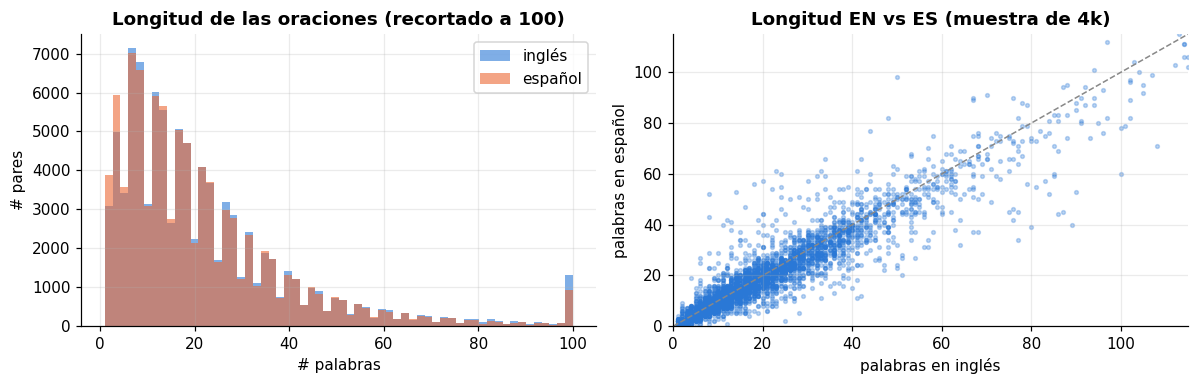

In [35]:
df_mt = pd.DataFrame({"en": [t["en"] for t in raw_mt["train"]["translation"]],
                      "es": [t["es"] for t in raw_mt["train"]["translation"]]})
df_mt["len_en"] = df_mt["en"].str.split().str.len()
df_mt["len_es"] = df_mt["es"].str.split().str.len()
df_mt["ratio"] = df_mt["len_es"] / df_mt["len_en"].clip(lower=1)

print(f"Pares: {len(df_mt):,} | duplicados exactos: {df_mt.duplicated(['en','es']).sum():,}")
print(f"Vacíos: en={(df_mt['len_en'] == 0).sum()}, es={(df_mt['len_es'] == 0).sum()}")
display(df_mt[["len_en", "len_es", "ratio"]].describe().round(2))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].hist(df_mt["len_en"].clip(upper=100), bins=60, alpha=0.6, color=COLORS[0], label="inglés")
axes[0].hist(df_mt["len_es"].clip(upper=100), bins=60, alpha=0.6, color=COLORS[1], label="español")
axes[0].set(title="Longitud de las oraciones (recortado a 100)", xlabel="# palabras", ylabel="# pares")
axes[0].legend()
s = df_mt.sample(4000, random_state=SEED)
axes[1].scatter(s["len_en"], s["len_es"], s=6, alpha=0.3, color=COLORS[0])
lim = max(s["len_en"].quantile(.99), s["len_es"].quantile(.99))
axes[1].plot([0, lim], [0, lim], "--", color="#888", lw=1)
axes[1].set(xlim=(0, lim), ylim=(0, lim), title="Longitud EN vs ES (muestra de 4k)",
            xlabel="palabras en inglés", ylabel="palabras en español")
plt.tight_layout(); plt.show()

In [36]:
print("Ejemplos de pares de traducción:\n")
for _, r in df_mt.sample(4, random_state=3).iterrows():
    print("EN:", wrap(r["en"])); print("ES:", wrap(r["es"])); print()

print("Ejemplos de pares sospechosos (proporción de longitudes extrema):\n")
for _, r in df_mt[(df_mt["ratio"] > 3) & (df_mt["len_en"] > 3)].head(2).iterrows():
    print("EN:", wrap(r["en"])); print("ES:", wrap(r["es"])); print()

Ejemplos de pares de traducción:

EN: And yesterday things went on just as usual.
ES: Y ayer todo pasaba como de costumbre.

EN: As regards the assertion that this is a basin and not a helmet I have already given an answer; but as to the
question whether this is a pack-saddle or a caparison I will not venture to give a positive opinion, but will
leave it to your worships' better judgment.
ES: En lo que toca a lo que dicen que ésta es bacía, y no yelmo, ya yo tengo respondido; pero, en lo de declarar
si ésa es albarda o jaez, no me atrevo a dar sentencia difinitiva: sólo lo dejo al buen parecer de vuestras
mercedes.

EN: "Wait a minute longer, and I will introduce him to you."
ES: Esperad un instante, voy a recomendaros a él.

EN: Far better would it be for us who have adopted this accursed service to go back to our own houses, and there
employ ourselves in pleasanter occupations—in hunting or fishing, for instance; for what squire in the world
is there so poor as not to have a hack and

**Observaciones del EDA y limpieza**

- Las oraciones literarias son largas y variadas (mediana de 17 palabras en inglés y 16 en español, con casos de más de 600). Hay diálogos, nombres propios y español antiguo, como en las traducciones del *Quijote* (“vuestras mercedes”, “bacía”, “yelmo”).
- La proporción de longitudes ES/EN es en promedio ~1.0, pero con extremos de 0.03 a 75.
- Como el corpus se alineó automáticamente, hay **pares mal alineados**: por ejemplo, “"A dance!" cried Marianne.” está emparejada con un párrafo entero en español. Se eliminan los pares vacíos, los 678 duplicados exactos y los pares con proporción de longitudes extrema (< 0.33 o > 3): en total **1 880 pares (2 %)**, y quedan 91 590.
- Este filtro **no detecta todo el ruido**: quedan metadatos (“Source: Project Gutenberg…”), pares con longitud parecida pero contenido distinto y hasta oraciones en francés del lado “inglés”, como se ve más adelante en la evaluación. Esto penaliza el BLEU de cualquier modelo y es una limitación del corpus.
- El 100 % de las traducciones de referencia cabe en 128 subtokens (percentil 95: 81).

In [37]:
def is_clean(ex):
    en, es = ex["translation"]["en"].strip(), ex["translation"]["es"].strip()
    if not en or not es:
        return False
    r = len(es.split()) / max(len(en.split()), 1)
    return 1 / 3 <= r <= 3

clean_mt = raw_mt["train"].filter(is_clean)
# eliminar duplicados exactos
seen, keep = set(), []
for i, t in enumerate(clean_mt["translation"]):
    key = (t["en"], t["es"])
    if key not in seen:
        seen.add(key); keep.append(i)
clean_mt = clean_mt.select(keep)
print(f"Pares tras la limpieza: {len(clean_mt):,} (se eliminaron {len(raw_mt['train']) - len(clean_mt):,})")

split1 = clean_mt.train_test_split(test_size=0.10, seed=SEED)
split2 = split1["test"].train_test_split(test_size=0.50, seed=SEED)
mt_ds = DatasetDict(train=split1["train"], validation=split2["train"], test=split2["test"])
mt_ds

Filter:   0%|          | 0/93470 [00:00<?, ? examples/s]

Pares tras la limpieza: 91,590 (se eliminaron 1,880)


DatasetDict({
    train: Dataset({
        features: ['id', 'translation'],
        num_rows: 82431
    })
    validation: Dataset({
        features: ['id', 'translation'],
        num_rows: 4579
    })
    test: Dataset({
        features: ['id', 'translation'],
        num_rows: 4580
    })
})

## C.4 Tokenización

In [38]:
MT_MAX_LEN = 128
tok_mt = AutoTokenizer.from_pretrained(MT_CHECKPOINT)

def preprocess_mt(batch):
    src = [t["en"] for t in batch["translation"]]
    tgt = [t["es"] for t in batch["translation"]]
    return tok_mt(src, text_target=tgt, max_length=MT_MAX_LEN, truncation=True)

mt_tok = mt_ds.map(preprocess_mt, batched=True, remove_columns=mt_ds["train"].column_names)

ex = mt_tok["train"][0]
print("Entrada (subtokens):", tok_mt.convert_ids_to_tokens(ex["input_ids"])[:25])
print("Salida  (subtokens):", tok_mt.convert_ids_to_tokens(ex["labels"])[:25])
lens = np.array([len(x) for x in mt_tok["train"].select(range(5000))["labels"]])
print(f"Subtokens de salida — p95: {np.percentile(lens, 95):.0f} | % que caben en {MT_MAX_LEN}: {(lens <= MT_MAX_LEN).mean():.1%}")

config.json:   0%|          | 0.00/1.47k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/44.0 [00:00<?, ?B/s]

source.spm:   0%|          | 0.00/802k [00:00<?, ?B/s]

target.spm:   0%|          | 0.00/826k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.59M [00:00<?, ?B/s]

Map:   0%|          | 0/82431 [00:00<?, ? examples/s]

Map:   0%|          | 0/4579 [00:00<?, ? examples/s]

Map:   0%|          | 0/4580 [00:00<?, ? examples/s]

Entrada (subtokens): ['▁V', 'ron', 'sky', "'", 's', '▁un', 'f', 'lin', 'ching', '▁eye', '▁glance', 'd', '▁in', '▁as', 'ton', 'ish', 'ment', '▁at', '▁the', '▁old', '▁Prince', ',', '▁and', '▁slightly', '▁smiling']
Salida  (subtokens): ['▁V', 'ron', 'sky', ',', '▁más', '▁extraña', 'do', '▁aún', ',', '▁con', 'te', 'mp', 'ló', '▁al', '▁Príncipe', '▁con', '▁sus', '▁ojos', '▁tranquilo', 's', '.', '▁Luego', '▁empezó', '▁a', '▁hablar']
Subtokens de salida — p95: 81 | % que caben en 128: 100.0%


## C.5 Funciones de entrenamiento y evaluación

In [39]:
import sacrebleu

def compute_metrics_mt(eval_preds):
    preds, labels = eval_preds
    if isinstance(preds, tuple):
        preds = preds[0]
    preds = np.where(preds != -100, preds, tok_mt.pad_token_id)
    labels = np.where(labels != -100, labels, tok_mt.pad_token_id)
    dec_preds = [p.strip() for p in tok_mt.batch_decode(preds, skip_special_tokens=True)]
    dec_labels = [l.strip() for l in tok_mt.batch_decode(labels, skip_special_tokens=True)]
    return {"bleu": sacrebleu.corpus_bleu(dec_preds, [dec_labels]).score,
            "chrf": sacrebleu.corpus_chrf(dec_preds, [dec_labels]).score,
            "gen_len": float(np.mean([np.count_nonzero(p != tok_mt.pad_token_id) for p in preds]))}

def make_mt_trainer(model, train_ds, eval_ds, lr, batch_size, epochs, output_dir, final=False,
                    num_beams=1, weight_decay=0.01):
    args = Seq2SeqTrainingArguments(
        output_dir=output_dir,
        learning_rate=lr,
        per_device_train_batch_size=batch_size,
        per_device_eval_batch_size=64,
        num_train_epochs=epochs,
        weight_decay=weight_decay,
        warmup_steps=warmup_steps_for(len(train_ds), batch_size, epochs) if train_ds is not None else 0,
        eval_strategy="epoch",
        save_strategy="epoch" if final else "no",
        load_best_model_at_end=final,
        metric_for_best_model="bleu",
        greater_is_better=True,
        save_total_limit=1,
        logging_steps=50,
        predict_with_generate=True,
        generation_max_length=MT_MAX_LEN,
        generation_num_beams=num_beams,
        fp16=USE_FP16,
        report_to="none",
        seed=SEED,
    )
    return Seq2SeqTrainer(model=model, args=args, train_dataset=train_ds, eval_dataset=eval_ds,
                          processing_class=tok_mt, data_collator=DataCollatorForSeq2Seq(tok_mt, model=model),
                          compute_metrics=compute_metrics_mt)

def train_mt(train_ds, eval_ds, lr, batch_size, epochs, output_dir, final=False):
    model = AutoModelForSeq2SeqLM.from_pretrained(MT_CHECKPOINT)
    trainer = make_mt_trainer(model, train_ds, eval_ds, lr, batch_size, epochs, output_dir, final)
    t0 = time.time()
    trainer.train()
    elapsed = time.time() - t0
    return trainer, trainer.evaluate(), elapsed

@torch.no_grad()
def translate(texts, model, batch_size=32, num_beams=4):
    model.eval()
    out = []
    for i in range(0, len(texts), batch_size):
        enc = tok_mt(texts[i:i + batch_size], return_tensors="pt", padding=True,
                     truncation=True, max_length=MT_MAX_LEN).to(model.device)
        gen = model.generate(**enc, num_beams=num_beams, max_new_tokens=MT_MAX_LEN)
        out.extend(tok_mt.batch_decode(gen, skip_special_tokens=True))
    return out

## C.6 Línea base: modelo preentrenado **sin** fine-tuning

In [40]:
N_SEARCH_VAL_MT = 500
search_val_mt = mt_tok["validation"].shuffle(seed=SEED).select(range(N_SEARCH_VAL_MT))

base_model = AutoModelForSeq2SeqLM.from_pretrained(MT_CHECKPOINT).to(DEVICE)
base_trainer = make_mt_trainer(base_model, None, search_val_mt, 1e-5, 32, 1, f"{OUT_DIR}/mt_base")
base_metrics = base_trainer.evaluate()
print(f"Línea base (sin fine-tuning) en {N_SEARCH_VAL_MT} oraciones de validación: "
      f"BLEU={base_metrics['eval_bleu']:.2f} | chrF={base_metrics['eval_chrf']:.2f}")
del base_trainer, base_model; free_memory()

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  312MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/258 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  312MB            

model.safetensors: downloading bytes:           |  0.00B            

generation_config.json:   0%|          | 0.00/293 [00:00<?, ?B/s]

{'eval_loss': '2.325', 'eval_model_preparation_time': '0.0042', 'eval_bleu': '16.6', 'eval_chrf': '44.16', 'eval_gen_len': '31.26', 'eval_runtime': '15.85', 'eval_samples_per_second': '31.54', 'eval_steps_per_second': '0.505', 'epoch': 0}
Línea base (sin fine-tuning) en 500 oraciones de validación: BLEU=16.60 | chrF=44.16


## C.7 Búsqueda de hiperparámetros sobre una muestra

Muestra de **10 000 pares** de entrenamiento, 1 época, evaluación con BLEU sobre 500 oraciones de validación (decodificación *greedy* para que sea rápido).

1. **Learning rate:** `1e-5, 2e-5, 5e-5, 1e-4` con *batch size* 32. Como el modelo ya traduce bien, un LR muy alto puede hacerle “olvidar” lo aprendido (*catastrophic forgetting*).
2. **Batch size:** con el mejor LR, 16 vs. 32.

Loading weights:   0%|          | 0/258 [00:00<?, ?it/s]

{'loss': '2.296', 'grad_norm': '3.714', 'learning_rate': '9.362e-06', 'epoch': '0.1597'}
{'loss': '2.289', 'grad_norm': '3.158', 'learning_rate': '7.589e-06', 'epoch': '0.3195'}
{'loss': '2.29', 'grad_norm': '3.367', 'learning_rate': '5.816e-06', 'epoch': '0.4792'}
{'loss': '2.28', 'grad_norm': '3.323', 'learning_rate': '4.043e-06', 'epoch': '0.639'}
{'loss': '2.276', 'grad_norm': '3.393', 'learning_rate': '2.27e-06', 'epoch': '0.7987'}
{'loss': '2.279', 'grad_norm': '3.102', 'learning_rate': '4.965e-07', 'epoch': '0.9585'}
{'eval_loss': '2.172', 'eval_bleu': '18.58', 'eval_chrf': '44.8', 'eval_gen_len': '30.84', 'eval_runtime': '14.73', 'eval_samples_per_second': '33.93', 'eval_steps_per_second': '0.543', 'epoch': '1'}
{'train_runtime': '79.07', 'train_samples_per_second': '126.5', 'train_steps_per_second': '3.959', 'train_loss': '2.285', 'epoch': '1'}
{'eval_loss': '2.172', 'eval_bleu': '18.58', 'eval_chrf': '44.8', 'eval_gen_len': '30.84', 'eval_runtime': '14.64', 'eval_samples_per_

Loading weights:   0%|          | 0/258 [00:00<?, ?it/s]

{'loss': '2.279', 'grad_norm': '3.769', 'learning_rate': '1.872e-05', 'epoch': '0.1597'}
{'loss': '2.271', 'grad_norm': '3.218', 'learning_rate': '1.518e-05', 'epoch': '0.3195'}
{'loss': '2.27', 'grad_norm': '3.37', 'learning_rate': '1.163e-05', 'epoch': '0.4792'}
{'loss': '2.257', 'grad_norm': '3.277', 'learning_rate': '8.085e-06', 'epoch': '0.639'}
{'loss': '2.252', 'grad_norm': '3.382', 'learning_rate': '4.539e-06', 'epoch': '0.7987'}
{'loss': '2.252', 'grad_norm': '3.056', 'learning_rate': '9.929e-07', 'epoch': '0.9585'}
{'eval_loss': '2.146', 'eval_bleu': '18.94', 'eval_chrf': '45.05', 'eval_gen_len': '30.71', 'eval_runtime': '14.72', 'eval_samples_per_second': '33.98', 'eval_steps_per_second': '0.544', 'epoch': '1'}
{'train_runtime': '79.07', 'train_samples_per_second': '126.5', 'train_steps_per_second': '3.958', 'train_loss': '2.263', 'epoch': '1'}
{'eval_loss': '2.146', 'eval_bleu': '18.94', 'eval_chrf': '45.05', 'eval_gen_len': '30.71', 'eval_runtime': '14.57', 'eval_samples_p

Loading weights:   0%|          | 0/258 [00:00<?, ?it/s]

{'loss': '2.262', 'grad_norm': '4.049', 'learning_rate': '4.681e-05', 'epoch': '0.1597'}
{'loss': '2.264', 'grad_norm': '3.177', 'learning_rate': '3.794e-05', 'epoch': '0.3195'}
{'loss': '2.259', 'grad_norm': '3.566', 'learning_rate': '2.908e-05', 'epoch': '0.4792'}
{'loss': '2.24', 'grad_norm': '3.206', 'learning_rate': '2.021e-05', 'epoch': '0.639'}
{'loss': '2.233', 'grad_norm': '3.374', 'learning_rate': '1.135e-05', 'epoch': '0.7987'}
{'loss': '2.225', 'grad_norm': '3.013', 'learning_rate': '2.482e-06', 'epoch': '0.9585'}
{'eval_loss': '2.117', 'eval_bleu': '19.06', 'eval_chrf': '45.15', 'eval_gen_len': '30.74', 'eval_runtime': '15.7', 'eval_samples_per_second': '31.86', 'eval_steps_per_second': '0.51', 'epoch': '1'}
{'train_runtime': '80.27', 'train_samples_per_second': '124.6', 'train_steps_per_second': '3.899', 'train_loss': '2.246', 'epoch': '1'}
{'eval_loss': '2.117', 'eval_bleu': '19.06', 'eval_chrf': '45.15', 'eval_gen_len': '30.74', 'eval_runtime': '15.16', 'eval_samples_pe

Loading weights:   0%|          | 0/258 [00:00<?, ?it/s]

{'loss': '2.262', 'grad_norm': '3.987', 'learning_rate': '9.362e-05', 'epoch': '0.1597'}
{'loss': '2.296', 'grad_norm': '3.22', 'learning_rate': '7.589e-05', 'epoch': '0.3195'}
{'loss': '2.285', 'grad_norm': '3.619', 'learning_rate': '5.816e-05', 'epoch': '0.4792'}
{'loss': '2.259', 'grad_norm': '3.278', 'learning_rate': '4.043e-05', 'epoch': '0.639'}
{'loss': '2.243', 'grad_norm': '3.428', 'learning_rate': '2.27e-05', 'epoch': '0.7987'}
{'loss': '2.227', 'grad_norm': '2.966', 'learning_rate': '4.965e-06', 'epoch': '0.9585'}
{'eval_loss': '2.112', 'eval_bleu': '18.77', 'eval_chrf': '44.95', 'eval_gen_len': '31.01', 'eval_runtime': '15.33', 'eval_samples_per_second': '32.62', 'eval_steps_per_second': '0.522', 'epoch': '1'}
{'train_runtime': '79.55', 'train_samples_per_second': '125.7', 'train_steps_per_second': '3.935', 'train_loss': '2.26', 'epoch': '1'}
{'eval_loss': '2.112', 'eval_bleu': '18.77', 'eval_chrf': '44.95', 'eval_gen_len': '31.01', 'eval_runtime': '15.51', 'eval_samples_pe

,learning_rate,batch_size,eval_loss,bleu,chrf,tiempo_s
2,0.00005,32,2.116848,19.063606,45.152738,81
1,0.00002,32,2.145640,18.940922,45.054473,79
3,0.00010,32,2.112436,18.765455,44.952227,80
0,0.00001,32,2.171891,18.584603,44.804031,79


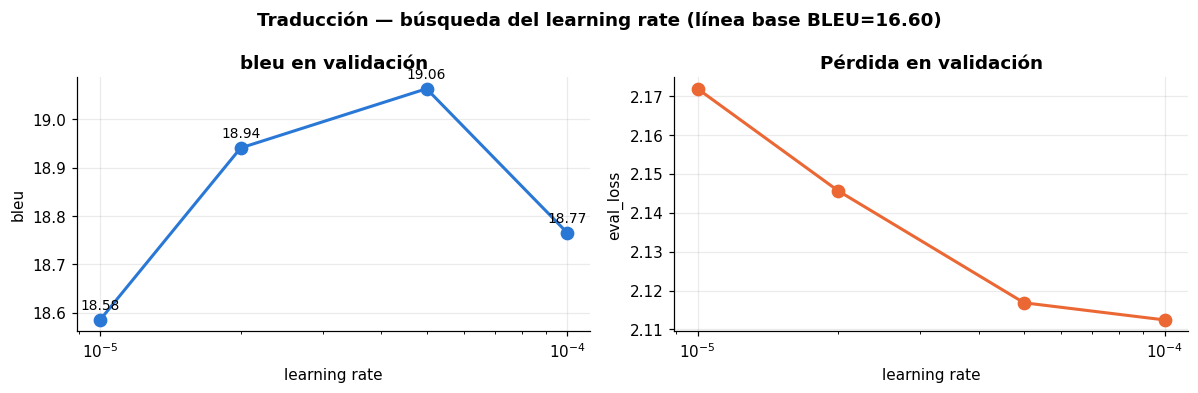

In [41]:
N_SEARCH_TRAIN_MT = 10000
SEARCH_EPOCHS_MT = 1
LR_GRID_MT = [1e-5, 2e-5, 5e-5, 1e-4]

search_train_mt = mt_tok["train"].shuffle(seed=SEED).select(range(N_SEARCH_TRAIN_MT))
search_mt = []
for lr in LR_GRID_MT:
    trainer, m, t = train_mt(search_train_mt, search_val_mt, lr, 32, SEARCH_EPOCHS_MT, f"{OUT_DIR}/mt_search")
    search_mt.append({"learning_rate": lr, "batch_size": 32, "eval_loss": m["eval_loss"],
                      "bleu": m["eval_bleu"], "chrf": m["eval_chrf"], "tiempo_s": round(t)})
    print(search_mt[-1])
    del trainer; free_memory()

df_search_mt = pd.DataFrame(search_mt)
display(df_search_mt.sort_values("bleu", ascending=False))
plot_search(df_search_mt, "bleu", f"Traducción — búsqueda del learning rate (línea base BLEU={base_metrics['eval_bleu']:.2f})")

In [42]:
best_lr_mt = df_search_mt.loc[df_search_mt["bleu"].idxmax(), "learning_rate"]
trainer, m, t = train_mt(search_train_mt, search_val_mt, best_lr_mt, 16, SEARCH_EPOCHS_MT, f"{OUT_DIR}/mt_search")
search_mt.append({"learning_rate": best_lr_mt, "batch_size": 16, "eval_loss": m["eval_loss"],
                  "bleu": m["eval_bleu"], "chrf": m["eval_chrf"], "tiempo_s": round(t)})
del trainer; free_memory()

df_search_mt = pd.DataFrame(search_mt)
display(df_search_mt.sort_values("bleu", ascending=False))
best_cfg_mt = df_search_mt.loc[df_search_mt["bleu"].idxmax()]
BEST_LR_MT, BEST_BS_MT = float(best_cfg_mt["learning_rate"]), int(best_cfg_mt["batch_size"])
print(f"✅ Mejor configuración: learning_rate={BEST_LR_MT}, batch_size={BEST_BS_MT}, BLEU={best_cfg_mt['bleu']:.2f}")

Loading weights:   0%|          | 0/258 [00:00<?, ?it/s]

{'loss': '2.263', 'grad_norm': '5.583', 'learning_rate': '3.952e-05', 'epoch': '0.08'}
{'loss': '2.227', 'grad_norm': '4.697', 'learning_rate': '4.671e-05', 'epoch': '0.16'}
{'loss': '2.315', 'grad_norm': '5.118', 'learning_rate': '4.227e-05', 'epoch': '0.24'}
{'loss': '2.208', 'grad_norm': '4.152', 'learning_rate': '3.783e-05', 'epoch': '0.32'}
{'loss': '2.254', 'grad_norm': '4.63', 'learning_rate': '3.339e-05', 'epoch': '0.4'}
{'loss': '2.258', 'grad_norm': '6.085', 'learning_rate': '2.895e-05', 'epoch': '0.48'}
{'loss': '2.213', 'grad_norm': '5.158', 'learning_rate': '2.451e-05', 'epoch': '0.56'}
{'loss': '2.283', 'grad_norm': '4.96', 'learning_rate': '2.007e-05', 'epoch': '0.64'}
{'loss': '2.255', 'grad_norm': '4.283', 'learning_rate': '1.563e-05', 'epoch': '0.72'}
{'loss': '2.203', 'grad_norm': '4.364', 'learning_rate': '1.119e-05', 'epoch': '0.8'}
{'loss': '2.177', 'grad_norm': '5.553', 'learning_rate': '6.75e-06', 'epoch': '0.88'}
{'loss': '2.255', 'grad_norm': '4.511', 'learnin

,learning_rate,batch_size,eval_loss,bleu,chrf,tiempo_s
4,0.00005,16,2.115196,19.147291,45.081964,87
2,0.00005,32,2.116848,19.063606,45.152738,81
1,0.00002,32,2.145640,18.940922,45.054473,79
3,0.00010,32,2.112436,18.765455,44.952227,80
0,0.00001,32,2.171891,18.584603,44.804031,79


✅ Mejor configuración: learning_rate=5e-05, batch_size=16, BLEU=19.15


## C.8 Entrenamiento con la data completa

Entrenando con 82,431 pares | lr=5e-05 | batch=16 | épocas=2


Loading weights:   0%|          | 0/258 [00:00<?, ?it/s]

{'loss': '2.358', 'grad_norm': '4.921', 'learning_rate': '2.379e-06', 'epoch': '0.009705'}
{'loss': '2.338', 'grad_norm': '4.727', 'learning_rate': '4.806e-06', 'epoch': '0.01941'}
{'loss': '2.279', 'grad_norm': '5.847', 'learning_rate': '7.233e-06', 'epoch': '0.02911'}
{'loss': '2.369', 'grad_norm': '5.042', 'learning_rate': '9.66e-06', 'epoch': '0.03882'}
{'loss': '2.311', 'grad_norm': '4.95', 'learning_rate': '1.209e-05', 'epoch': '0.04852'}
{'loss': '2.252', 'grad_norm': '5.501', 'learning_rate': '1.451e-05', 'epoch': '0.05823'}
{'loss': '2.305', 'grad_norm': '4.897', 'learning_rate': '1.694e-05', 'epoch': '0.06793'}
{'loss': '2.306', 'grad_norm': '4.762', 'learning_rate': '1.937e-05', 'epoch': '0.07764'}
{'loss': '2.224', 'grad_norm': '5.249', 'learning_rate': '2.18e-05', 'epoch': '0.08734'}
{'loss': '2.23', 'grad_norm': '6.837', 'learning_rate': '2.422e-05', 'epoch': '0.09705'}
{'loss': '2.249', 'grad_norm': '4.769', 'learning_rate': '2.665e-05', 'epoch': '0.1068'}
{'loss': '2.23

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

{'loss': '1.862', 'grad_norm': '4.364', 'learning_rate': '2.752e-05', 'epoch': '1.009'}
{'loss': '1.839', 'grad_norm': '4.193', 'learning_rate': '2.725e-05', 'epoch': '1.019'}
{'loss': '1.813', 'grad_norm': '4.705', 'learning_rate': '2.698e-05', 'epoch': '1.029'}
{'loss': '1.782', 'grad_norm': '4.693', 'learning_rate': '2.671e-05', 'epoch': '1.038'}
{'loss': '1.861', 'grad_norm': '5.6', 'learning_rate': '2.644e-05', 'epoch': '1.048'}
{'loss': '1.83', 'grad_norm': '4.809', 'learning_rate': '2.618e-05', 'epoch': '1.058'}
{'loss': '1.815', 'grad_norm': '4.243', 'learning_rate': '2.591e-05', 'epoch': '1.068'}
{'loss': '1.9', 'grad_norm': '5.361', 'learning_rate': '2.564e-05', 'epoch': '1.077'}
{'loss': '1.781', 'grad_norm': '4.272', 'learning_rate': '2.537e-05', 'epoch': '1.087'}
{'loss': '1.794', 'grad_norm': '5.181', 'learning_rate': '2.51e-05', 'epoch': '1.097'}
{'loss': '1.822', 'grad_norm': '4.533', 'learning_rate': '2.483e-05', 'epoch': '1.106'}
{'loss': '1.848', 'grad_norm': '4.352'

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

{'train_runtime': '1252', 'train_samples_per_second': '131.7', 'train_steps_per_second': '8.231', 'train_loss': '1.96', 'epoch': '2'}
{'eval_loss': '1.878', 'eval_bleu': '22.16', 'eval_chrf': '46.58', 'eval_gen_len': '29.18', 'eval_runtime': '28', 'eval_samples_per_second': '35.71', 'eval_steps_per_second': '0.571', 'epoch': '2'}
Tiempo de entrenamiento: 20.9 min
{'eval_loss': 1.8776326179504395, 'eval_bleu': 22.157003342849443, 'eval_chrf': 46.577092447435135, 'eval_gen_len': 29.175, 'eval_runtime': 28.0042, 'eval_samples_per_second': 35.709, 'eval_steps_per_second': 0.571, 'epoch': 2.0}


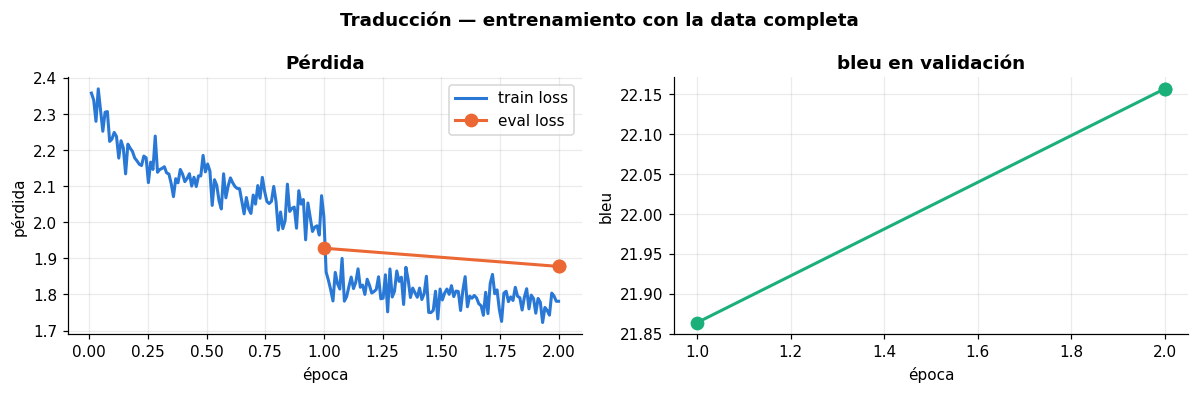

In [43]:
N_TRAIN_FULL_MT = None        # None = todo el conjunto de entrenamiento limpio
EPOCHS_FULL_MT = 2
N_VAL_FULL_MT = 1000          # oraciones de validación evaluadas en cada época

full_train_mt = mt_tok["train"] if N_TRAIN_FULL_MT is None else \
    mt_tok["train"].shuffle(seed=SEED).select(range(N_TRAIN_FULL_MT))
val_full_mt = mt_tok["validation"].shuffle(seed=SEED).select(range(min(N_VAL_FULL_MT, len(mt_tok["validation"]))))
print(f"Entrenando con {len(full_train_mt):,} pares | lr={BEST_LR_MT} | batch={BEST_BS_MT} | épocas={EPOCHS_FULL_MT}")

trainer_mt, val_metrics_mt, time_mt = train_mt(full_train_mt, val_full_mt, BEST_LR_MT, BEST_BS_MT,
                                               EPOCHS_FULL_MT, f"{OUT_DIR}/mt_final", final=True)
print(f"Tiempo de entrenamiento: {time_mt/60:.1f} min")
print(val_metrics_mt)
plot_history(trainer_mt, "bleu", "Traducción — entrenamiento con la data completa")

## C.9 Evaluación en el conjunto de prueba: línea base vs. modelo ajustado

Se traducen 2 000 oraciones de prueba con *beam search* (4 haces) usando ambos modelos.

Loading weights:   0%|          | 0/258 [00:00<?, ?it/s]

,modelo,BLEU,chrF
0,opus-mt-en-es (sin ajustar),17.54,44.61
1,opus-mt-en-es + fine-tuning (nuestro),22.67,47.70


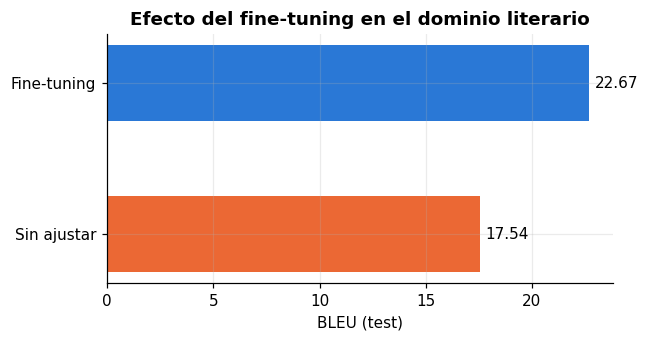

In [44]:
N_TEST_MT = 2000
test_pairs = mt_ds["test"].shuffle(seed=SEED).select(range(min(N_TEST_MT, len(mt_ds["test"]))))["translation"]
src_test = [p["en"] for p in test_pairs]
ref_test = [p["es"] for p in test_pairs]

ft_model = trainer_mt.model
hyp_ft = translate(src_test, ft_model)
base_model = AutoModelForSeq2SeqLM.from_pretrained(MT_CHECKPOINT).to(DEVICE)
hyp_base = translate(src_test, base_model)

res_mt = pd.DataFrame({
    "modelo": ["opus-mt-en-es (sin ajustar)", "opus-mt-en-es + fine-tuning (nuestro)"],
    "BLEU": [sacrebleu.corpus_bleu(hyp_base, [ref_test]).score, sacrebleu.corpus_bleu(hyp_ft, [ref_test]).score],
    "chrF": [sacrebleu.corpus_chrf(hyp_base, [ref_test]).score, sacrebleu.corpus_chrf(hyp_ft, [ref_test]).score],
}).round(2)
display(res_mt)

fig, ax = plt.subplots(figsize=(6, 3.2))
ax.barh(["Sin ajustar", "Fine-tuning"], res_mt["BLEU"], color=[COLORS[1], COLORS[0]], height=0.5)
for i, v in enumerate(res_mt["BLEU"]):
    ax.annotate(f"{v:.2f}", (v, i), textcoords="offset points", xytext=(4, 0), va="center")
ax.set(xlabel="BLEU (test)", title="Efecto del fine-tuning en el dominio literario")
plt.tight_layout(); plt.show()

In [45]:
# Comparación cualitativa
comp = pd.DataFrame({"inglés": src_test, "referencia": ref_test, "sin ajustar": hyp_base, "fine-tuning": hyp_ft})
for _, r in comp.sample(5, random_state=7).iterrows():
    print("EN :", wrap(r["inglés"])); print("REF:", wrap(r["referencia"]))
    print("BASE:", wrap(r["sin ajustar"])); print("FT :", wrap(r["fine-tuning"])); print()
del base_model; free_memory()

EN : It could be done.
REF: Llevaron el carricoche.
BASE: Podría hacerse.
FT : Podía hacerse.

EN : Quoi qu’il en fut, Ferrier restait un célibataire endurci.
REF: El caso es que, por la causa que fuere, Ferrier permaneció estrictamente célibe.
BASE: Quoi qu’il en fut, Ferrier restait un célibataire endurci.
FT : Al final, Ferrier repuso un célibati.

EN : Memories of childhood and of Levin's friendship with her dead brother lent a peculiar poetic charm to her
relations with him.
REF: Aquellos recuerdos de la infancia, la memoria de Levin unida a la del hermano difunto, nimbaba de poéticos
colores sus relaciones con él.
BASE: Recuerdos de la infancia y de la amistad de Levin con su hermano muerto le prestaron un encanto poético
peculiar a sus relaciones con él.
FT : Los recuerdos de la infancia y la amistad de Levin con su hermano muerto le daban un encanto poético
particular a sus relaciones con él.

EN : Certainly, if the wind did not moderate, it would take a longer time to reach Li

## C.10 Mejor modelo: guardado y demostración

In [46]:
FINAL_MT_DIR = os.path.join(BASE_DIR, "opus-mt-en-es-books")
trainer_mt.save_model(FINAL_MT_DIR)
save_result("C_traduccion", {
    "dataset": f"{MT_DATASET} ({MT_CONFIG})", "modelo_base": MT_CHECKPOINT,
    "learning_rate": BEST_LR_MT, "batch_size": BEST_BS_MT, "epocas": EPOCHS_FULL_MT,
    "n_train": len(full_train_mt), "tiempo_min": round(time_mt / 60, 1),
    "test_bleu_base": float(res_mt.loc[0, "BLEU"]), "test_bleu": float(res_mt.loc[1, "BLEU"]),
    "test_chrf_base": float(res_mt.loc[0, "chrF"]), "test_chrf": float(res_mt.loc[1, "chrF"]),
    "busqueda": df_search_mt.to_dict(orient="records"),
})

frases_en = [
    "It was a dark and stormy night; the rain fell in torrents.",
    "\"I am not afraid of you,\" she said, looking straight into his eyes.",
    "He had never seen so beautiful a garden in all his life.",
]
for en, es in zip(frases_en, translate(frases_en, trainer_mt.model)):
    print(f"EN: {en}\nES: {es}\n")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

EN: It was a dark and stormy night; the rain fell in torrents.
ES: Era una noche oscura y tormentosa; la lluvia caía en torrentes.

EN: "I am not afraid of you," she said, looking straight into his eyes.
ES: -No le temo -dijo, mirándole a los ojos-.

EN: He had never seen so beautiful a garden in all his life.
ES: Jamás había visto un jardín tan hermoso en toda su vida.



### Conclusiones y análisis de resultados — Parte C (Traducción Automática Seq2Seq - OPUS Books)

1. **Impacto cuantitativo de la adaptación de dominio** (2 000 oraciones de prueba, *beam search* de 4 haces):
   - **Modelo base (`Helsinki-NLP/opus-mt-en-es` sin ajustar):** BLEU = **17.54** | chrF = **44.61**
   - **MarianMT con *fine-tuning* (nuestro):** BLEU = **22.67** | chrF = **47.70**
   - **Ganancia:** **+5.13 puntos de BLEU** (+29.2 % relativo) y **+3.09 puntos de chrF**, con 82 431 pares, 2 épocas y 20.9 min en una T4.
   - Aunque MarianMT ya era un traductor competente, el ajuste lo adaptó al estilo de las traducciones literarias del corpus.

2. **Búsqueda del learning rate (10 000 pares, 1 época):**
   - Con solo 10 000 pares, todas las configuraciones ya superaban la línea base (BLEU de 16.60 en validación).
   - El mejor fue **learning rate = $5 \times 10^{-5}$** (BLEU 19.06, chrF 45.15). $1 \times 10^{-5}$ fue el más lento en adaptarse (18.58).
   - Con $1 \times 10^{-4}$ el BLEU bajó a 18.77. Esto es consistente con que un learning rate alto empieza a deteriorar lo aprendido en el preentrenamiento (*catastrophic forgetting*), pero la caída es pequeña y se midió en solo 500 oraciones, así que no se puede afirmar con certeza.
   - Además, la **pérdida de validación siguió bajando con $1 \times 10^{-4}$** aunque el BLEU empeoró: la pérdida y la métrica de generación no siempre coinciden, por eso se eligió por BLEU.
   - Batch 16 frente a 32 fue prácticamente un empate (19.15 vs. 19.06); se eligió 16.

3. **Curva de entrenamiento:** el BLEU de validación seguía subiendo en la época 2 (21.86 → 22.16) y la pérdida seguía bajando (1.93 → 1.88), así que más épocas probablemente darían una mejora adicional.

4. **Análisis cualitativo:**
   - **Raya de diálogo:** en la demostración, el modelo ajustado usa la convención española “-No le temo -dijo, mirándole a los ojos-.”, en lugar de copiar las comillas del inglés.
   - **Tiempos verbales narrativos:** “si el viento no se moderaba, se necesitaría más tiempo…”, frente al literal “si el viento no se modera, tomaría un tiempo más largo…” del modelo base.
   - **Convenciones de las traducciones del corpus:** en un fragmento de *Anna Karenina*, el modelo ajustado escribe “Peszov” y “Sergio Ivanovich”, igual que la traducción de referencia, mientras el modelo base deja “PESTSOV” y “Koznyshev”. El modelo aprendió cómo nombra los personajes esa traducción en particular.

5. **Limitaciones de BLEU y del corpus:**
   - Algunas referencias no corresponden a la oración fuente: “It could be done.” está emparejada con “Llevaron el carricoche.”.
   - Hay oraciones en francés del lado “inglés”. Ante una de ellas, el modelo base copió el texto sin traducir y el ajustado produjo una frase sin sentido (“Al final, Ferrier repuso un célibati.”).
   - BLEU usa una sola referencia y penaliza paráfrasis válidas. chrF, que mide coincidencias de caracteres, es más tolerante a la morfología del español.
   - Por todo esto, el BLEU absoluto es bajo para ambos modelos, y la comparación relativa y el análisis cualitativo son más informativos que el número aislado.
   - **División por oraciones, no por libros:** entrenamiento y prueba salen de los mismos libros. Parte de la mejora (como los nombres de *Anna Karenina*) refleja que el modelo ya vio esas obras; con libros nunca vistos la ganancia probablemente sería menor.

---
# Resumen: mejores modelos encontrados

In [47]:
with open(RESULTS_PATH) as f:
    R = json.load(f)

filas = []
if "A_sentimiento" in R:
    r = R["A_sentimiento"]
    filas.append({"Tarea": "A. Sentimiento (clasificación)", "Modelo base": r["modelo_base"],
                  "LR": r["learning_rate"], "Batch": r["batch_size"], "Épocas": r["epocas"], "N train": r["n_train"],
                  "Métrica principal (test)": f"F1 macro = {r['test_f1_macro']:.4f} (acc = {r['test_accuracy']:.4f})"})
if "B_ner" in R:
    r = R["B_ner"]
    filas.append({"Tarea": "B. NER (etiquetado)", "Modelo base": r["modelo_base"],
                  "LR": r["learning_rate"], "Batch": r["batch_size"], "Épocas": r["epocas"], "N train": r["n_train"],
                  "Métrica principal (test)": f"F1 entidad = {r['test_f1']:.4f}"})
if "C_traduccion" in R:
    r = R["C_traduccion"]
    filas.append({"Tarea": "C. Traducción EN→ES (seq2seq)", "Modelo base": r["modelo_base"],
                  "LR": r["learning_rate"], "Batch": r["batch_size"], "Épocas": r["epocas"], "N train": r["n_train"],
                  "Métrica principal (test)": f"BLEU = {r['test_bleu']:.2f} (base {r['test_bleu_base']:.2f})"})
display(pd.DataFrame(filas))

,Tarea,Modelo base,LR,Batch,Épocas,N train,Métrica principal (test)
0,A. Sentimiento (clasificación),dccuchile/bert-base-spanish-wwm-cased,0.00003,32,2,200000,F1 macro = 0.7341 (acc = 0.7896)
1,B. NER (etiquetado),dccuchile/bert-base-spanish-wwm-cased,0.00008,16,5,8324,F1 entidad = 0.8691
2,C. Traducción EN→ES (seq2seq),Helsinki-NLP/opus-mt-en-es,0.00005,16,2,82431,BLEU = 22.67 (base 17.54)


## Conclusiones generales del proyecto

Se implementó el ciclo completo de *fine-tuning* de modelos Transformer preentrenados para tres tipos de problemas: clasificación de secuencias, etiquetado de secuencias y generación secuencia a secuencia, en español.

---

### 1. Síntesis de resultados

| Dimensión | A. Clasificación de secuencias | B. Etiquetado de secuencias (NER) | C. Secuencia a secuencia (MT) |
|:---|:---|:---|:---|
| **Problema** | Sentimiento en reseñas de Amazon | Entidades nombradas en noticias | Traducción literaria inglés $\to$ español |
| **Dataset** | `amazon_reviews_multi_es` (200k train) | `conll2002` es (8.3k train) | `opus_books` en-es (82.4k train limpios) |
| **Arquitectura** | BETO (*encoder-only*, BERT-base, ~110M) | BETO (*encoder-only*, BERT-base, ~110M) | MarianMT (*encoder-decoder*, ~77M) |
| **Hiperparámetros elegidos** | LR = $3 \times 10^{-5}$, batch = 32, 2 épocas | LR = $8 \times 10^{-5}$, batch = 16, 5 épocas (mejor: época 3) | LR = $5 \times 10^{-5}$, batch = 16, 2 épocas |
| **Tiempo de entrenamiento completo (T4)** | 34.8 min | 5.0 min | 20.9 min |
| **Línea base** | Accuracy = 40.00 % (clase mayoritaria) | — (accuracy por token engañosa: ~88 % `O`) | BLEU = 17.54 \| chrF = 44.61 (sin *fine-tuning*) |
| **Desempeño en test** | **Accuracy = 78.96 %** <br> **F1 macro = 0.7341** | **F1 micro entidad = 0.8691** <br> F1 macro = 0.8550 | **BLEU = 22.67** (+5.13) <br> **chrF = 47.70** (+3.09) |
| **Métrica clave** | F1 macro (sensible a la clase neutral) | F1 exacto por entidad (`seqeval`) | sacreBLEU y chrF |

---

### 2. Lo que mostró la búsqueda de hiperparámetros

- **El learning rate fue el hiperparámetro que más movió los resultados, y el batch size casi no influyó.** En las tres tareas, el valor más bajo ($1 \times 10^{-5}$ o $2 \times 10^{-5}$) fue el peor con pocas épocas, y el mejor estuvo entre $3 \times 10^{-5}$ y $8 \times 10^{-5}$.
- **Las diferencias fueron pequeñas:** entre los mejores valores, de 0.5 a 2 puntos, del mismo orden que la variación entre corridas. Lo confirma que este notebook se ejecutó dos veces y los resultados finales variaron alrededor de medio punto (por ejemplo, F1 de NER 0.875 vs. 0.869). Para conclusiones firmes habría que repetir con varias semillas.
- **Buscar en una muestra es barato:** entre 5 y 9 minutos por tarea, frente a 5–35 minutos de cada entrenamiento completo.
- **Casos particulares:** en NER el mejor learning rate quedó en el borde de la rejilla. En traducción, la pérdida y el BLEU no coincidieron con $1 \times 10^{-4}$, lo que muestra que hay que elegir con la métrica que importa.

---

### 3. Preprocesamiento y métricas

1. **Alineación de subtokens en NER:** *WordPiece* parte las palabras, así que la etiqueta se asignó solo al primer subtoken y los demás se enmascararon con `-100`. La evaluación con `seqeval` solo premia la entidad completa con el tipo y los límites correctos.
2. **Desbalance y etiquetas ruidosas en clasificación:** el F1 macro hizo visible la dificultad de la clase `neutral` (F1 = 0.4810, frente a más de 0.84 en positivo y negativo). El 92 % de los errores involucra esa clase; las reseñas de 3★ mezclan pros y contras, y su etiqueta (las estrellas) no siempre coincide con el texto.
3. **Métricas de traducción:** BLEU mostró una ganancia de más de 5 puntos, y chrF la confirmó. El análisis cualitativo mostró cambios de estilo (raya de diálogo, tiempos narrativos) que BLEU no siempre premia, porque compara con una sola referencia.

---

### 4. Limitaciones y trabajo futuro

- **Exploración limitada:** por las cuotas de GPU, la búsqueda se hizo en dos etapas (primero el learning rate y luego el batch size), con una sola semilla y sobre muestras. Se podría usar optimización bayesiana (p. ej., Optuna) y varias semillas para estimar la variabilidad. En NER conviene probar learning rates mayores a $8 \times 10^{-5}$; en traducción, más épocas.
- **Calidad de los datos:** etiquetas de sentimiento derivadas de estrellas, anotaciones inconsistentes en CoNLL-2002 (comillas dentro o fuera de la entidad) y pares desalineados o en otro idioma en OPUS Books. Además, en traducción la división fue por oraciones y no por libros, lo que probablemente infla la mejora.
- **Modelos más grandes:** **RoBERTa-BNE** (MarIA, de la Biblioteca Nacional de España y el BSC) para clasificación y NER, o **mBART**/**mT5** para traducción.
- **Evaluación de traducción:** una limpieza más estricta (p. ej., detección de idioma), evaluación humana de adecuación y fluidez, y métricas neuronales como **COMET**.